# IADS5 · Trabajo práctico integrador — Ortelana Textil
### Cuaderno de actividades evaluables · 16 clases · TODOs abiertos

**Alumno/a:** [Nombre y apellido]  
**Comisión:** [Completar]  
**Repositorio GitHub:** [URL]  
**Fecha:** [Completar]

**Propósito.** Desarrollar, justificar y defender un proyecto de aprendizaje automático de principio a fin usando `ventas_historicas_ortelana_argentina.csv`. Este cuaderno organiza las consignas del **TP integrador oficial** con espacios de trabajo, interpretación y devolución docente. **No incluye soluciones ni pasos de implementación guiados.**

**Modalidad de entrega del enunciado:** el TP original pide un notebook distinto por actividad (`actividad_01.ipynb` a `actividad_16.ipynb`), un mismo split reutilizado y commits progresivos. Este archivo es una **plantilla maestra**: para entregar, separá cada actividad en su propio notebook y mantené las decisiones y los índices de partición reproducibles. Hitos: clases 5 y 13 (parciales), clase 16 (final con defensa).

## Reglas comunes y decisiones de adaptación

- Dataset: **Ortelana Textil**. Verificá que cumpla los requisitos del TP: **≥500 filas**, variables numéricas y categóricas, target claro y ausencia de proxies directos del target.
- **Problema principal:** clasificación multiclase de `Format_Reporte` (si el CSV contiene esa columna). Usá el significado de las clases que surja de los datos/documentación; no inventes interpretaciones.
- **Problema secundario de regresión:** para las actividades que lo requieren, proponé un **target numérico legítimo** disponible en Ortelana, por ejemplo `Metros1` *solo si su predicción es justificable*. Excluí ese target de las features y evitá variables que lo revelen directa o indirectamente. Documentá las decisiones. **No conviertas códigos arbitrarios de categorías en una variable continua por conveniencia.**
- Reservá **20% para test** una sola vez (`random_state=42`; estratificá el target de clasificación). Conservá y reutilizá los mismos índices para comparar modelos dentro de cada problema. Para el problema de regresión, explicá la partición y su relación con el split original.
- No utilices el test para elegir hiperparámetros: seleccioná con validación cruzada sobre entrenamiento. El enunciado original solicita métricas de test en varias actividades; reportalas cuando corresponda, pero reconocé que **consultarlo repetidamente puede sesgar las decisiones**.
- Desde la actividad 9, el preprocesamiento supervisado debe integrarse en un `Pipeline` y validarse sin data leakage. Para clustering, no uses el target como feature.
- Justificá todas las decisiones. Cada TODO es **abierto**: debés escribir el código y explicar por qué lo elegiste.

**Dependencias sugeridas:** pandas, numpy, matplotlib, seaborn (opcional), scikit-learn, xgboost, scipy, joblib. Registrá versiones en la entrega final.

## Preparación y reproducibilidad

Ubicá el CSV junto al notebook (o indicá una ruta relativa reproducible). Confirmá nombres reales de columnas, tipos y disponibilidad de librerías. Documentá cualquier adaptación necesaria.

In [1]:
# Preparación: librerías, versiones y carga del dataset
import sys, time, platform, hashlib, warnings, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy, sklearn, joblib, xgboost

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, StratifiedGroupKFold,
                                     cross_val_score, cross_validate, cross_val_predict,
                                     GridSearchCV, learning_curve, validation_curve)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from xgboost import XGBClassifier

# Transformaciones propias: viven en src/ para que el pipeline serializado sea portable
from src.ortelana_ml import COLUMNAS_ENTRADA, agregar_features, ClasificadorEtiquetado

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})

RUTA_DATOS = Path('ventas_historicas_ortelana_argentina.csv')   # ruta relativa al notebook
DIR_DATA, DIR_MODELS, DIR_OUT = Path('data'), Path('models'), Path('outputs')
for carpeta in (DIR_DATA, DIR_MODELS, DIR_OUT):
    carpeta.mkdir(exist_ok=True)

VERSIONES = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
             'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__, 'scipy': scipy.__version__,
             'matplotlib': matplotlib.__version__, 'joblib': joblib.__version__}
print(pd.Series(VERSIONES).to_string())

df_raw = pd.read_csv(RUTA_DATOS)
print('\nFilas y columnas:', df_raw.shape)
display(df_raw.head())

python          3.12.3
numpy            2.1.0
pandas           3.0.5
scikit-learn     1.9.0
xgboost          3.4.1
scipy           1.18.1
matplotlib      3.10.0
joblib           1.6.0

Filas y columnas: (3285, 16)


,Sucursal_ID,Año,Tela_ID,Format_Reporte,Metros1,Metros2,Metros3,Metros4,Metros5,Metros6,Metros7,Metros8,Metros9,Metros10,Metros11,Metros12
0,1,2016,TELA-001,S,5826.63,5919.77,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2016,TELA-002,C,2747.21,2081.75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,2016,TELA-003,S,3711.95,3752.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,2016,TELA-004,B,1275.78,1798.45,1923.95,1861.88,1747.80,1233.24,NaN,NaN,NaN,NaN,NaN,NaN
4,1,2016,TELA-005,M,240.05,241.48,321.98,384.31,396.75,355.00,340.77,383.03,401.43,306.25,278.83,235.65


In [2]:
# Definiciones compartidas por todas las actividades
TARGET_CLF = 'Format_Reporte'                     # problema principal: clasificación multiclase
TARGET_REG = 'Metros_Total'                       # problema secundario: regresión (ver Act. 4)
METROS = [f'Metros{i}' for i in range(1, 13)]
NUM_CLF = ['Año', 'log_M1', 'log_ratio_M2_M1']    # numéricas de la tarea principal
CAT_ID = ['Sucursal_ID', 'Tela_ID']               # identificadores -> se tratan como categóricas
CLASES = sorted(df_raw[TARGET_CLF].unique())

df = agregar_features(df_raw)                                  # transformaciones fila a fila
df[TARGET_REG] = df_raw[METROS].sum(axis=1, min_count=1)       # metros vendidos en el año
df['Par_Suc_Tela'] = df['Sucursal_ID'].astype(str) + '|' + df['Tela_ID']

requisitos = pd.Series({
    'Filas (requisito >= 500)': len(df_raw),
    'Columnas numéricas': df_raw.select_dtypes('number').shape[1],
    'Columnas de texto/categóricas': df_raw.select_dtypes(exclude='number').shape[1],
    'Clases del target': df_raw[TARGET_CLF].nunique(),
    'Faltantes en el target': int(df_raw[TARGET_CLF].isna().sum()),
})
display(requisitos.to_frame('Valor'))

# Validación cruzada y registro histórico de métricas de test
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
cv5_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
HISTORICO = []

def metricas_clf(y_true, y_pred):
    return {'Accuracy': accuracy_score(y_true, y_pred),
            'F1_macro': f1_score(y_true, y_pred, average='macro'),
            'F1_weighted': f1_score(y_true, y_pred, average='weighted')}

def metricas_reg(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MAE': mean_absolute_error(y_true, y_pred), 'MSE': mse,
            'RMSE': np.sqrt(mse), 'R2': r2_score(y_true, y_pred)}

def registrar(actividad, tarea, modelo, metricas):
    HISTORICO.append({'Actividad': actividad, 'Tarea': tarea, 'Modelo': modelo, **metricas})

def tabla_historica(tarea):
    h = pd.DataFrame(HISTORICO)
    return h[h['Tarea'] == tarea].drop(columns='Tarea').dropna(axis=1, how='all').set_index('Modelo')

,Valor
Filas (requisito >= 500),3285
Columnas numéricas,14
Columnas de texto/categóricas,2
Clases del target,4
Faltantes en el target,0


**Registro de decisiones compartidas**

- **Ruta del dataset:** `ventas_historicas_ortelana_argentina.csv`, en la misma carpeta que el notebook (variable `RUTA_DATOS`, ruta relativa). Las transformaciones propias están en `src/ortelana_ml.py`, que el notebook importa.
- **Target principal de clasificación y significado:** `Format_Reporte`, con 4 clases (B, C, M, S). El dataset no trae diccionario de datos, así que el significado sale de los datos: cada formato tiene una cantidad fija de columnas `Metros` con dato (**B → 6, M → 12, C y S → 2**), y la suma de esas columnas da un total anual comparable entre formatos (medianas de 2.338 a 2.743 m). Es decir, el formato indica **en cuántos períodos se partió la venta anual del registro**. B y M son consistentes con un reporte bimestral y uno mensual; C y S tienen 2 períodos con perfiles distintos (en C el segundo período es ≈ 0,77 veces el primero; en S, ≈ 1). No les ponemos un nombre a C y S porque los datos no lo confirman.
- **Target secundario de regresión y justificación:** `Metros_Total` = `Metros1 + … + Metros12`, los metros vendidos en el año por sucursal y tela. Es una cantidad real del negocio y **no depende del formato** (el R² es el mismo con o sin `Format_Reporte`, Act. 4). `Metros1` lo descartamos como target porque, según el formato, representa un mes, un bimestre o un período de medio año: predecirlo es en buena parte predecir el formato (R² de 0,32 a 0,64 al agregar `Format_Reporte`).
- **Features incluidas/excluidas y motivos:**
  - Clasificación: `Año`, `Metros1` y `Metros2` (siempre completas para todas las clases), transformadas fila a fila en `log_M1` = log(1+Metros1) y `log_ratio_M2_M1` = log((1+Metros2)/(1+Metros1)). `Sucursal_ID` y `Tela_ID` se evaluaron con one-hot y **se excluyeron del modelo final** porque llevan a memorizar el formato de cada par sucursal-tela (Act. 9).
  - **Excluidas: `Metros3`…`Metros12`.** Que tengan o no dato determina el formato (proxy directo del target).
  - Regresión: `Año` + `Sucursal_ID` + `Tela_ID` como one-hot (y la interacción sucursal×tela desde la Act. 4). Se excluyen todas las `Metros*` (son los componentes del target) y `Format_Reporte` (no aporta y es el otro target).
- **Identificadores de train/test persistidos en:** `data/split_indices.csv` (índice de fila → `train`/`test`). La partición es 80/20, estratificada por `Format_Reporte`, con `random_state=42`. La regresión usa **los mismos índices**.
- **Riesgos de fuga temporal, por sucursal o por columnas proxy:**
  1. *Proxy por faltantes:* las columnas `Metros3..12` revelan el formato, así que se excluyen.
  2. *Dependencia entre registros:* los 360 pares sucursal-tela tienen **siempre el mismo formato** en los 10 años, y el 100% de los pares de test también aparece en train. Con los IDs como features, el modelo memoriza el par y la evaluación queda inflada. Por eso validamos además con `StratifiedGroupKFold` agrupando por par.
  3. *Temporal:* el split aleatorio mezcla años (se entrena con 2025 y se evalúa en 2016). En la regresión eso implica usar el "futuro" de una misma serie. Lo dejamos como limitación documentada.
  4. *Misma fila:* `Metros1` y `Metros2` son partes de la misma venta anual (correlación 0,906), así que no se usan para predecir `Metros_Total`.

---
## Actividad 01 · Framing, EDA y split de datos

**Qué se espera:** Definí el problema, explorá filas, tipos, faltantes y distribución del target; reservá 20% para test y construí la baseline de clasificación (y la de regresión cuando corresponda).

**Evidencia a entregar:** EDA documentada; partición persistida y reproducible; predicciones de baseline.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [3]:
# 1.1 Estructura general: tipos, faltantes, duplicados y cardinalidad
resumen = pd.DataFrame({
    'tipo': df_raw.dtypes.astype(str),
    'faltantes': df_raw.isna().sum(),
    '% faltantes': (df_raw.isna().mean() * 100).round(1),
    'valores únicos': df_raw.nunique(),
})
display(resumen)
print('Filas duplicadas:', df_raw.duplicated().sum())
print('Máximo de filas por (Sucursal, Año, Tela):',
      df_raw.groupby(['Sucursal_ID', 'Año', 'Tela_ID']).size().max(),
      '-> cada fila es una combinación única sucursal-año-tela')
display(df[['Metros1', 'Metros2', TARGET_REG]].describe().T.round(1))

,tipo,faltantes,% faltantes,valores únicos
Sucursal_ID,int64,0,0.0,12
Año,int64,0,0.0,10
Tela_ID,str,0,0.0,30
Format_Reporte,str,0,0.0,4
Metros1,float64,0,0.0,3258
Metros2,float64,0,0.0,3253
Metros3,float64,1788,54.4,1479
Metros4,float64,1788,54.4,1479
Metros5,float64,1788,54.4,1486
Metros6,float64,1788,54.4,1480


Filas duplicadas: 0
Máximo de filas por (Sucursal, Año, Tela): 1 -> cada fila es una combinación única sucursal-año-tela


,count,mean,std,min,25%,50%,75%,max
Metros1,3285.0,960.7,1103.5,0.5,195.6,536.2,1376.2,9487.0
Metros2,3285.0,956.7,1015.8,0.5,238.3,655.0,1319.1,9293.6
Metros_Total,3285.0,3082.5,2330.4,7.6,1526.6,2526.7,4061.1,18780.6


In [4]:
# 1.2 Faltantes estructurales y dependencia entre registros
n_periodos = df_raw[METROS].notna().sum(axis=1).rename('Períodos con dato')
print('Cantidad de columnas Metros con dato según el formato:')
display(pd.crosstab(df_raw[TARGET_CLF], n_periodos))

# Si las columnas Metros son la misma venta anual partida en períodos, el total debería ser comparable
print('Medianas por formato [m]:')
display(df.groupby(TARGET_CLF)[['Metros1', 'Metros2', TARGET_REG]].median().round(1))

fmt_por_par = df.groupby('Par_Suc_Tela')[TARGET_CLF].nunique()
fmt_por_tela = df.groupby('Tela_ID')[TARGET_CLF].nunique()
print(f'Pares sucursal-tela: {fmt_por_par.size}; con un único formato en los 10 años: {(fmt_por_par == 1).sum()}')
print(f'Telas que usan más de un formato (según la sucursal): {(fmt_por_tela > 1).sum()} de {fmt_por_tela.size}')
print(f"Correlación Metros1-Metros2: {df['Metros1'].corr(df['Metros2']):.3f}")

Cantidad de columnas Metros con dato según el formato:


Períodos con dato,2,6,12
Format_Reporte,,,
B,0,732,0
C,860,0,0
M,0,0,765
S,928,0,0


Medianas por formato [m]:


,Metros1,Metros2,Metros_Total
Format_Reporte,,,
B,284.3,416.4,2369.0
C,1287.3,1051.4,2338.1
M,155.2,156.1,2743.1
S,1274.8,1333.5,2580.2


Pares sucursal-tela: 360; con un único formato en los 10 años: 360
Telas que usan más de un formato (según la sucursal): 30 de 30
Correlación Metros1-Metros2: 0.906


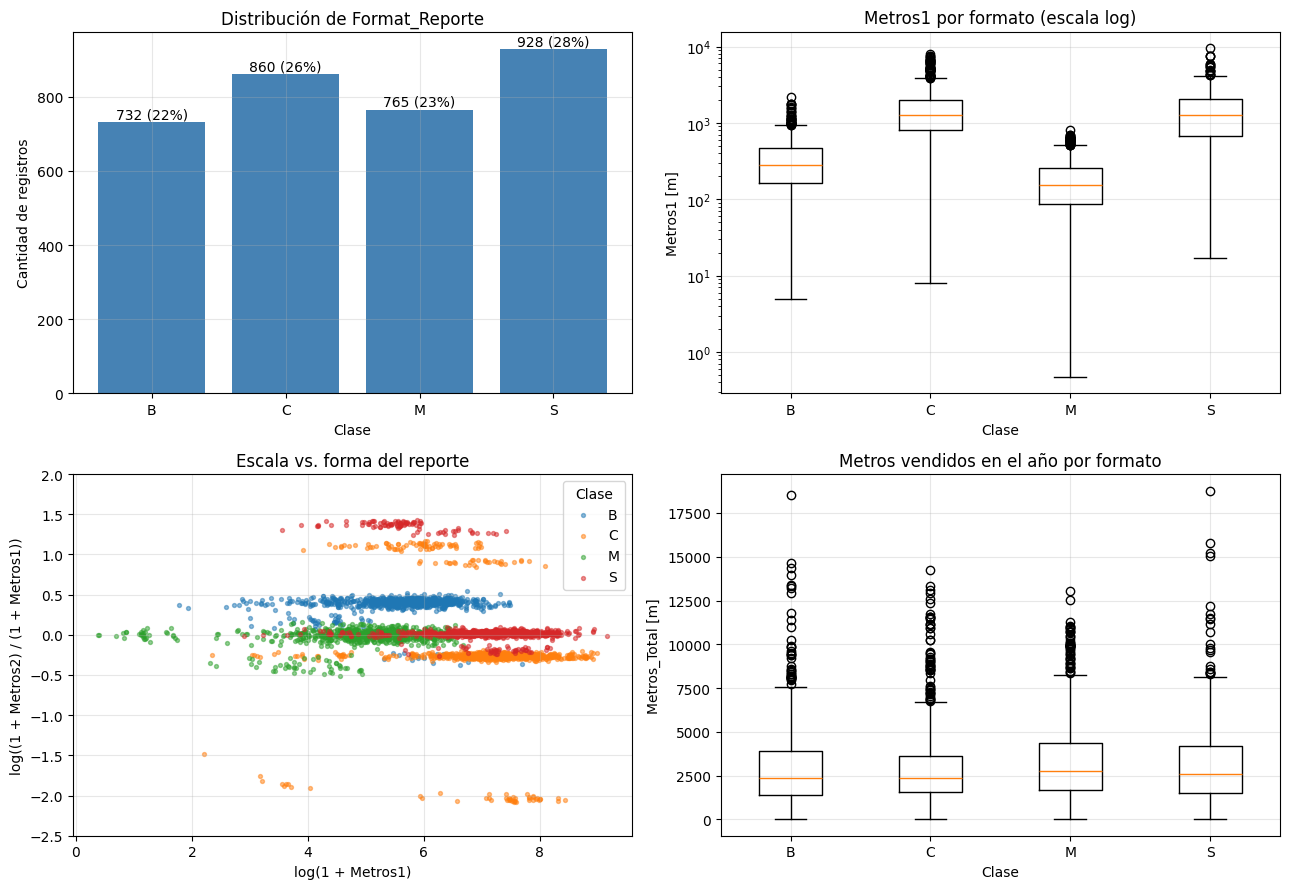

In [5]:
# 1.3 Distribución del target y relación con las variables candidatas
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
conteo = df[TARGET_CLF].value_counts().reindex(CLASES)
ax[0, 0].bar(CLASES, conteo, color='steelblue')
for i, v in enumerate(conteo):
    ax[0, 0].text(i, v + 10, f'{v} ({v / len(df):.0%})', ha='center')
ax[0, 0].set(title='Distribución de Format_Reporte', xlabel='Clase', ylabel='Cantidad de registros')

ax[0, 1].boxplot([df.loc[df[TARGET_CLF] == c, 'Metros1'] for c in CLASES], tick_labels=CLASES)
ax[0, 1].set_yscale('log')
ax[0, 1].set(title='Metros1 por formato (escala log)', xlabel='Clase', ylabel='Metros1 [m]')

for c in CLASES:
    sub = df[df[TARGET_CLF] == c]
    ax[1, 0].scatter(sub['log_M1'], sub['log_ratio_M2_M1'], s=8, alpha=0.5, label=c)
ax[1, 0].set(title='Escala vs. forma del reporte', xlabel='log(1 + Metros1)',
             ylabel='log((1 + Metros2) / (1 + Metros1))', ylim=(-2.5, 2))
ax[1, 0].legend(title='Clase')

ax[1, 1].boxplot([df.loc[df[TARGET_CLF] == c, TARGET_REG] for c in CLASES], tick_labels=CLASES)
ax[1, 1].set(title='Metros vendidos en el año por formato', xlabel='Clase', ylabel='Metros_Total [m]')
plt.tight_layout()
plt.show()

In [6]:
# 1.4 Partición única 80/20 estratificada por el target principal, persistida en disco
RUTA_SPLIT = DIR_DATA / 'split_indices.csv'
idx_tr, idx_te = train_test_split(df.index, test_size=0.2, random_state=RANDOM_STATE,
                                  stratify=df[TARGET_CLF])
particion = pd.Series('train', index=df.index, name='split').rename_axis('fila')
particion.loc[idx_te] = 'test'
particion.to_csv(RUTA_SPLIT)

# A partir de acá los índices se leen del archivo: no se vuelve a sortear la partición
particion = pd.read_csv(RUTA_SPLIT, index_col='fila')['split']
idx_train = particion.index[particion == 'train']
idx_test = particion.index[particion == 'test']
assert set(idx_train) == set(idx_tr) and set(idx_test) == set(idx_te)

train, test = df.loc[idx_train], df.loc[idx_test]
y_train, y_test = train[TARGET_CLF], test[TARGET_CLF]
yr_train, yr_test = train[TARGET_REG], test[TARGET_REG]   # regresión: mismos índices

print(f'Train: {len(train)} filas | Test: {len(test)} filas | archivo: {RUTA_SPLIT}')
display(pd.DataFrame({'train': y_train.value_counts(normalize=True),
                      'test': y_test.value_counts(normalize=True)}).reindex(CLASES).round(3))
print(f"Filas de test cuyo par sucursal-tela también aparece en train: "
      f"{test['Par_Suc_Tela'].isin(train['Par_Suc_Tela']).mean():.1%}")

Train: 2628 filas | Test: 657 filas | archivo: data\split_indices.csv


,train,test
Format_Reporte,,
B,0.223,0.222
C,0.262,0.262
M,0.233,0.233
S,0.282,0.283


Filas de test cuyo par sucursal-tela también aparece en train: 100.0%


In [7]:
# 1.5 Baselines: predicen sin aprender de las features
baseline_clf = DummyClassifier(strategy='most_frequent').fit(train[NUM_CLF], y_train)
baseline_reg = DummyRegressor(strategy='mean').fit(train[['Año']], yr_train)
pred_base_clf = baseline_clf.predict(test[NUM_CLF])
pred_base_reg = baseline_reg.predict(test[['Año']])

preds_baseline = pd.DataFrame({'Format_Reporte_real': y_test, 'Format_Reporte_baseline': pred_base_clf,
                               'Metros_Total_real': yr_test, 'Metros_Total_baseline': pred_base_reg.round(1)})
preds_baseline.to_csv(DIR_OUT / 'predicciones_baseline.csv')
print('Clase más frecuente en train:', baseline_clf.classes_[baseline_clf.class_prior_.argmax()],
      '| media de Metros_Total en train:', round(yr_train.mean(), 1), 'm')
display(preds_baseline.head())

Clase más frecuente en train: S | media de Metros_Total en train: 3093.4 m


,Format_Reporte_real,Format_Reporte_baseline,Metros_Total_real,Metros_Total_baseline
fila,,,,
5,M,S,5616.20,3093.4
13,C,S,4482.71,3093.4
14,B,S,13312.68,3093.4
18,M,S,1864.30,3093.4
21,S,S,6749.46,3093.4


### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- Exploramos estructura, tipos, faltantes, duplicados y cardinalidad. Cada fila es una combinación única sucursal-año-tela (12 sucursales × 30 telas × 10 años; no todas las combinaciones tienen los 10 años).
- Encontramos que los faltantes de `Metros3..12` **no son aleatorios sino estructurales**: dependen solo del formato. Por eso esas columnas quedan fuera como features.
- Derivamos dos features **fila a fila** (no aprenden nada del conjunto de datos, así que no generan fuga): el logaritmo de `Metros1` (porque la variable es muy asimétrica: va de 0,5 a 9.487 m) y el log del cociente `Metros2/Metros1`, que representa la "forma" del reporte entre los dos primeros períodos.
- Partición 80/20 estratificada por `Format_Reporte` (`random_state=42`), guardada en `data/split_indices.csv` y releída desde el archivo. La regresión reutiliza los mismos índices: estratificar por formato no sesga `Metros_Total`, porque su distribución es parecida en todos los formatos (último gráfico).
- Baselines: `DummyClassifier(most_frequent)` (predice siempre S) y `DummyRegressor(mean)` (predice siempre 3.093 m). Guardamos sus predicciones en `outputs/predicciones_baseline.csv`.
- Alternativas que consideramos: un split temporal (entrenar hasta 2023 y evaluar 2024-2025) o un split por par sucursal-tela. Mantuvimos el split aleatorio estratificado porque es el que pide la consigna, y medimos el riesgo de dependencia aparte (Act. 9).

**Interpretación de los resultados:**
- 3.285 filas y 16 columnas. No hay duplicados ni faltantes en `Sucursal_ID`, `Año`, `Tela_ID`, `Metros1`, `Metros2` y el target. Las clases están bastante balanceadas (22% a 28%), así que train y test quedaron con las mismas proporciones.
- La tabla de períodos es contundente: B tiene siempre 6 columnas con dato, M 12, y C y S 2. A pesar de eso, el total anual es similar entre formatos (medianas de 2.338 a 2.743 m). Las columnas `Metros` son la misma venta anual dividida en distintos períodos.
- En el gráfico de escala vs. forma, las clases aparecen como **bandas horizontales**. B tiene `Metros2 ≈ 1,5 × Metros1`, C tiene ≈ 0,77×, y M y S ≈ 1×; M y S se distinguen por la escala (los valores de M son mucho más chicos, coherente con períodos más cortos). Hay subgrupos chicos con cocientes extremos (C ≈ 0,13 y S ≈ 3,9) que se concentran en pocos pares.
- Los 360 pares sucursal-tela tienen un único formato en todos los años, y todas las telas usan más de un formato según la sucursal. El formato depende del **par**, no de la tela ni del año.

**Pregunta de análisis:** ¿Qué significa predecir `Format_Reporte` en Ortelana? ¿Qué riesgos de fuga o dependencia entre registros identificás?
Predecir `Format_Reporte` significa inferir, a partir de lo vendido en los dos primeros períodos, **con qué esquema de períodos fue cargado un registro**. Sirve para validar cargas, reconstruir el metadato cuando falta o detectar registros mal etiquetados al integrar datos de sucursales. Sin el formato correcto, un valor de `Metros1` puede leerse como un mes cuando en realidad es medio año.

Riesgos que identificamos:
1. **Proxy directo:** la cantidad de columnas `Metros` con dato determina el formato. Un modelo con `Metros3..12` (o con sus indicadores de faltante) "acertaría" sin aprender nada útil.
2. **Dependencia entre registros:** un par sucursal-tela repite su formato los 10 años, y el 100% de los pares de test está también en train. Si el modelo puede identificar el par (con `Sucursal_ID` y `Tela_ID`), la métrica de test mide memoria y no generalización.
3. **Temporal:** el split aleatorio usa años futuros para predecir años pasados.
4. **Dentro de la fila:** `Metros1` y `Metros2` están muy correlacionadas (0,906), así que no deben usarse para predecir un target construido con ellas.

**Limitaciones o mejoras posibles:**
No hay diccionario de datos, así que el significado exacto de C y S no se puede confirmar. Como mejora, conviene agregar una evaluación con split temporal o agrupado para medir la generalización a años o pares nuevos. Los subgrupos con cocientes extremos merecen una revisión con el área que carga los datos.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 02 · Métricas de la baseline

**Qué se espera:** Calculá accuracy, F1 y métricas por clase para clasificación; para la tarea de regresión calculá MAE, MSE, RMSE y R². Mostrá una tabla y la distribución del target.

**Evidencia a entregar:** Tabla de métricas y visualización del target.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [8]:
# 2.1 Baseline de clasificación: métricas globales y por clase (test)
m = metricas_clf(y_test, pred_base_clf)
registrar('01-02', 'Clasificación', 'Baseline (más frecuente)', m)
print(pd.Series(m).round(4).to_string(), '\n')
print(classification_report(y_test, pred_base_clf, zero_division=0, digits=3))

# Referencia estimada solo con train (CV10), con una segunda baseline que respeta las proporciones
for estrategia in ['most_frequent', 'stratified']:
    s = cross_val_score(DummyClassifier(strategy=estrategia, random_state=RANDOM_STATE),
                        train[NUM_CLF], y_train, cv=cv10, scoring='f1_macro')
    print(f'F1 macro CV10 baseline {estrategia:13s}: {s.mean():.4f} ± {s.std():.4f}')

Accuracy       0.2831
F1_macro       0.1103
F1_weighted    0.1249 

              precision    recall  f1-score   support

           B      0.000     0.000     0.000       146
           C      0.000     0.000     0.000       172
           M      0.000     0.000     0.000       153
           S      0.283     1.000     0.441       186

    accuracy                          0.283       657
   macro avg      0.071     0.250     0.110       657
weighted avg      0.080     0.283     0.125       657



F1 macro CV10 baseline most_frequent: 0.1101 ± 0.0004

F1 macro CV10 baseline stratified   : 0.2337 ± 0.0290


In [9]:
# 2.2 Baseline de regresión (predice siempre la media de train)
m = metricas_reg(yr_test, pred_base_reg)
registrar('01-02', 'Regresión', 'Baseline (media)', m)
display(pd.DataFrame([m], index=['Baseline media']).round(2))
print(f'Desvío estándar de Metros_Total en test: {yr_test.std():,.1f} m (el RMSE de la media es ≈ ese valor)')

,MAE,MSE,RMSE,R2
Baseline media,1673.04,5437191.59,2331.78,-0.0


Desvío estándar de Metros_Total en test: 2,332.9 m (el RMSE de la media es ≈ ese valor)


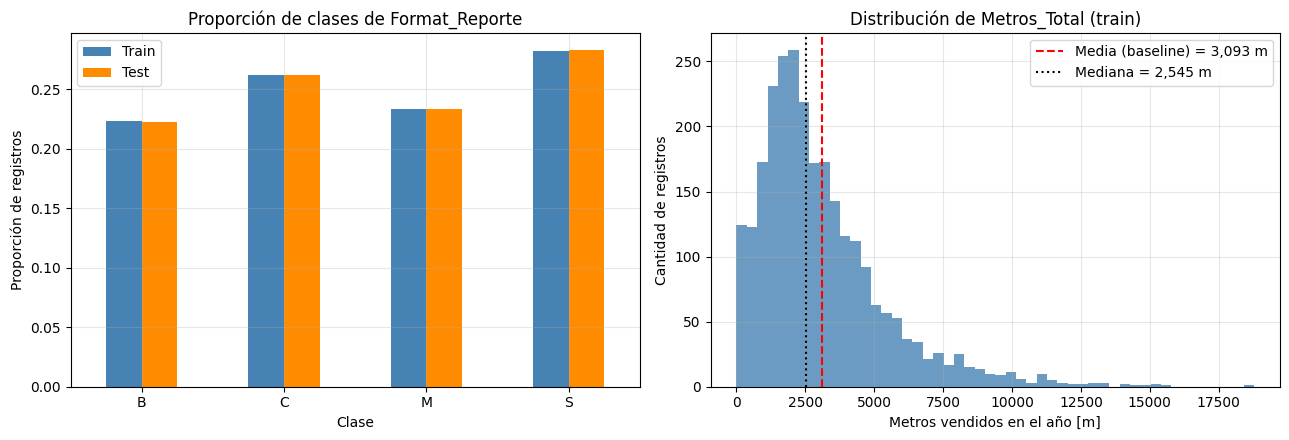

In [10]:
# 2.3 Visualización de ambos targets
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
prop = pd.DataFrame({'Train': y_train.value_counts(normalize=True),
                     'Test': y_test.value_counts(normalize=True)}).reindex(CLASES)
prop.plot.bar(ax=ax[0], rot=0, color=['steelblue', 'darkorange'])
ax[0].set(title='Proporción de clases de Format_Reporte', xlabel='Clase', ylabel='Proporción de registros')

ax[1].hist(yr_train, bins=50, color='steelblue', alpha=0.8)
ax[1].axvline(yr_train.mean(), color='red', ls='--', label=f'Media (baseline) = {yr_train.mean():,.0f} m')
ax[1].axvline(yr_train.median(), color='black', ls=':', label=f'Mediana = {yr_train.median():,.0f} m')
ax[1].set(title='Distribución de Metros_Total (train)', xlabel='Metros vendidos en el año [m]',
          ylabel='Cantidad de registros')
ax[1].legend()
plt.tight_layout()
plt.show()

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Métrica principal: F1 macro.** Promedia el F1 de cada clase con el mismo peso, así que castiga a un modelo que ignora clases enteras (como la baseline). Reportamos también accuracy, F1 ponderado y el `classification_report` por clase.
- Sumamos una segunda baseline (`stratified`, que sortea según las proporciones de train) para tener una referencia menos trivial, estimada con CV10 sobre train.
- Regresión: MAE, MSE, RMSE y R², todas en test y en las unidades del target (metros por año, salvo MSE en m² y R², que no tiene unidades).

**Interpretación de los resultados:**
- **Baseline de clasificación:** accuracy 0,283 (la proporción de S en test), F1 macro **0,110** y F1 ponderado 0,125. Solo S tiene F1 distinto de cero (0,441, con recall 1 y precisión 0,283). En CV10 da 0,110 ± 0,0004; la baseline estratificada llega a 0,234 ± 0,029. Cualquier modelo útil tiene que superar con claridad ese 0,11–0,23.
- **Baseline de regresión:** MAE 1.673 m, RMSE 2.332 m, R² ≈ 0. El RMSE coincide con el desvío estándar de `Metros_Total` en test (2.333 m), como corresponde a predecir la media.
- La distribución de `Metros_Total` es asimétrica a la derecha (media 3.093 m > mediana 2.545 m, con casos de hasta 18.780 m). Esa cola es la que separa el RMSE del MAE.

**Pregunta de análisis:** ¿Un F1=0,80 sería suficiente? ¿Qué costo tienen los errores en las distintas clases? ¿Cómo interpretás RMSE en la regresión elegida?
**F1 = 0,80** superaría ampliamente a la baseline, pero no lo consideramos suficiente: implica equivocarse más o menos en 1 de cada 5 registros, y en este problema los modelos de árboles llegan a ~0,94 (Act. 5–7). Además, los errores no cuestan lo mismo. Confundir **M con S o con C** (12 períodos contra 2) lleva a leer valores mensuales como si fueran semestrales, un error de escala de 6 a 12 veces si se usa el formato para reconstruir series. Confundir **B con M** (6 contra 12) también cambia la escala. **C contra S** es el error menos grave: los dos tienen 2 períodos y el mismo total anual, y solo cambia la forma de repartirlo. Por eso, además del F1 macro, conviene mirar el recall por clase de M y S.

**RMSE** está en metros vendidos por año. Es el error "típico" de la predicción, pero eleva los errores al cuadrado, así que pesa mucho los casos grandes de la cola. El RMSE de la baseline (2.332 m) es el piso que hay que bajar. Que el MAE sea bastante menor (1.673 m) indica que hay errores grandes ocasionales.

**Limitaciones o mejoras posibles:**
La baseline por clase mayoritaria es muy débil como referencia. Las métricas de test provienen de un único split, por lo que importan más las de CV. Para la regresión, se podría modelar el log del total para reducir el peso de la cola.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 03 · Primer modelo estadístico

**Qué se espera:** Entrená LogisticRegression para clasificación y LinearRegression para regresión con las variables numéricas adecuadas; compará con sus baselines. Analizá coeficientes y una matriz de confusión o gráfico real vs. predicho.

**Evidencia a entregar:** Métricas comparativas, coeficientes y visualización.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [11]:
# 3.1 Regresión logística multinomial: variables crudas vs. transformadas (escalado dentro del pipeline)
variantes = {'LogReg (Año, Metros1, Metros2 crudas)': ['Año', 'Metros1', 'Metros2'],
             'LogReg (Año, log_M1, log_ratio)': NUM_CLF}
filas = []
for nombre, cols in variantes.items():
    modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    s = cross_val_score(modelo, train[cols], y_train, cv=cv10, scoring='f1_macro')
    modelo.fit(train[cols], y_train)
    m = metricas_clf(y_test, modelo.predict(test[cols]))
    registrar('03', 'Clasificación', nombre, m)
    filas.append({'Modelo': nombre, 'F1_macro_CV10': s.mean(), 'Std_CV10': s.std(),
                  **{f'{k}_test': v for k, v in m.items()}})
logreg = modelo   # la última variante (features transformadas) es la que se analiza
filas.insert(0, {'Modelo': 'Baseline (más frecuente)', **{f'{k}_test': v for k, v in metricas_clf(y_test, pred_base_clf).items()}})
display(pd.DataFrame(filas).set_index('Modelo').round(4))

,Accuracy_test,F1_macro_test,F1_weighted_test,F1_macro_CV10,Std_CV10
Modelo,,,,,
Baseline (más frecuente),0.2831,0.1103,0.1249,NaN,NaN
"LogReg (Año, Metros1, Metros2 crudas)",0.7336,0.7296,0.7356,0.7115,0.0218
"LogReg (Año, log_M1, log_ratio)",0.7686,0.7686,0.7670,0.7600,0.0207


,Año,log_M1,log_ratio_M2_M1
B,-0.045,-0.743,1.121
C,0.045,0.764,-1.190
M,-0.105,-1.599,-0.929
S,0.105,1.578,0.997


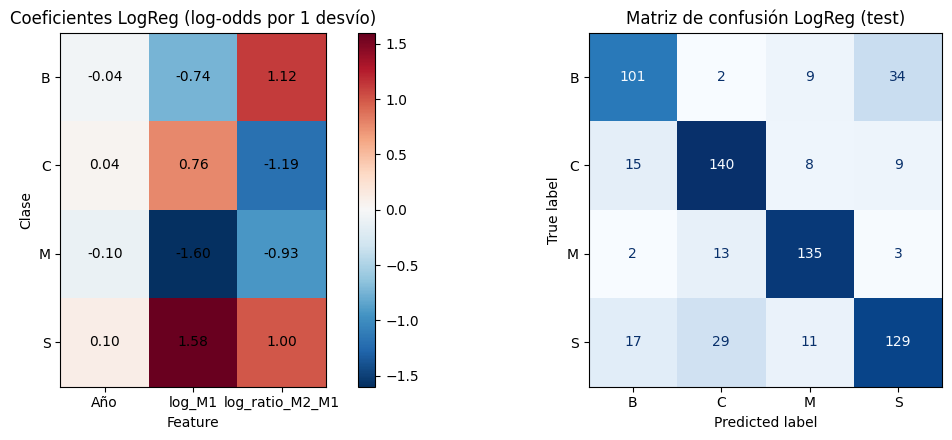

In [12]:
# 3.2 Coeficientes (features estandarizadas) y matriz de confusión
coefs = pd.DataFrame(logreg[-1].coef_, index=logreg[-1].classes_, columns=NUM_CLF)
display(coefs.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
lim = np.abs(coefs.values).max()
im = ax[0].imshow(coefs.values, cmap='RdBu_r', vmin=-lim, vmax=lim)
ax[0].set_xticks(range(len(NUM_CLF)), NUM_CLF)
ax[0].set_yticks(range(len(CLASES)), coefs.index)
for i in range(coefs.shape[0]):
    for j in range(coefs.shape[1]):
        ax[0].text(j, i, f'{coefs.iat[i, j]:.2f}', ha='center', va='center')
ax[0].set(title='Coeficientes LogReg (log-odds por 1 desvío)', xlabel='Feature', ylabel='Clase')
ax[0].grid(False)
fig.colorbar(im, ax=ax[0])
ConfusionMatrixDisplay.from_predictions(y_test, logreg.predict(test[NUM_CLF]), ax=ax[1],
                                        cmap='Blues', colorbar=False)
ax[1].set_title('Matriz de confusión LogReg (test)')
ax[1].grid(False)
plt.tight_layout()
plt.show()

In [13]:
# 3.3 Regresión lineal sobre Metros_Total.
# Sucursal_ID y Tela_ID son códigos arbitrarios: entran como indicadoras (one-hot), no como números.
FEAT_REG = ['Año'] + CAT_ID

def crear_prep_reg(cat_cols=CAT_ID):
    return ColumnTransformer([
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())]), ['Año']),
        ('cat', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))]), cat_cols)])

def evaluar_reg(nombre, modelo, cols, actividad=None):
    r = cross_validate(modelo, train[cols], yr_train, cv=cv5_reg,
                       scoring=('r2', 'neg_root_mean_squared_error'))
    modelo.fit(train[cols], yr_train)
    pred = modelo.predict(test[cols])
    m = metricas_reg(yr_test, pred)
    if actividad:
        registrar(actividad, 'Regresión', nombre, m)
    return {'Modelo': nombre, 'RMSE_CV5': -r['test_neg_root_mean_squared_error'].mean(),
            'R2_CV5': r['test_r2'].mean(), **{f'{k}_test': v for k, v in m.items()}}, pred

fila_base, _ = evaluar_reg('Baseline (media)', DummyRegressor(), FEAT_REG)
linreg = Pipeline([('prep', crear_prep_reg()), ('modelo', LinearRegression())])
fila_lin, pred_lin = evaluar_reg('LinearRegression (Año + sucursal + tela)', linreg, FEAT_REG, '03')
display(pd.DataFrame([fila_base, fila_lin]).set_index('Modelo').round(3))

,RMSE_CV5,R2_CV5,MAE_test,MSE_test,RMSE_test,R2_test
Modelo,,,,,,
Baseline (media),2327.698,-0.003,1673.040,5437191.589,2331.779,-0.001
LinearRegression (Año + sucursal + tela),1305.479,0.683,843.449,1618778.038,1272.312,0.702


Intercepto: 8,616.6 m (sucursal 1, TELA-001, año medio)


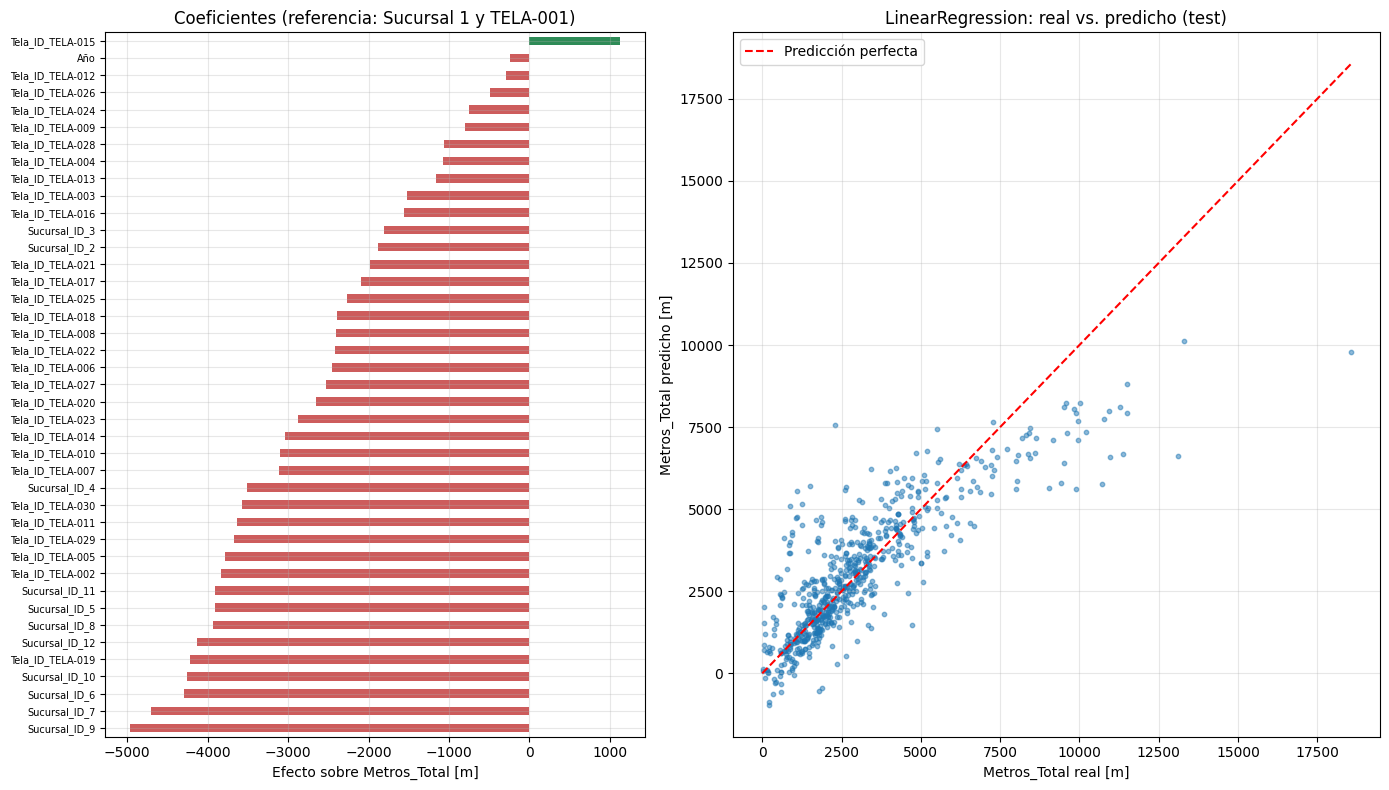

In [14]:
# 3.4 Coeficientes de la regresión lineal y gráfico real vs. predicho
nombres = [n.replace('num__', '').replace('cat__', '') for n in linreg[0].get_feature_names_out()]
coef_reg = pd.Series(linreg[-1].coef_, index=nombres).sort_values()
print(f'Intercepto: {linreg[-1].intercept_:,.1f} m (sucursal 1, TELA-001, año medio)')

fig, ax = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={'width_ratios': [1, 1.2]})
coef_reg.plot.barh(ax=ax[0], color=np.where(coef_reg > 0, 'seagreen', 'indianred'))
ax[0].set(title='Coeficientes (referencia: Sucursal 1 y TELA-001)', xlabel='Efecto sobre Metros_Total [m]')
ax[0].tick_params(axis='y', labelsize=7)
ax[1].scatter(yr_test, pred_lin, s=10, alpha=0.5)
tope = max(yr_test.max(), pred_lin.max())
ax[1].plot([0, tope], [0, tope], 'r--', label='Predicción perfecta')
ax[1].set(title='LinearRegression: real vs. predicho (test)', xlabel='Metros_Total real [m]',
          ylabel='Metros_Total predicho [m]')
ax[1].legend()
plt.tight_layout()
plt.show()

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Clasificación:** regresión logística multinomial con `StandardScaler` dentro de un `make_pipeline` (así el escalado se ajusta solo con train y los coeficientes son comparables entre features). Comparamos dos versiones: con `Año, Metros1, Metros2` crudas y con `Año, log_M1, log_ratio_M2_M1`. En la segunda, log(Metros2) − log(Metros1) convierte el cociente en una diferencia, algo que un modelo lineal puede representar.
- **Regresión:** `LinearRegression` sobre `Metros_Total` con `Año` (escalado) y `Sucursal_ID`/`Tela_ID` como **indicadoras one-hot** (`drop='first'`). Los IDs son códigos sin orden, así que tratarlos como números continuos sería inventar una relación lineal inexistente. Esas indicadoras son las "variables numéricas adecuadas" para este target.

**Interpretación de los resultados:**
- **LogReg:** con las features transformadas, F1 macro CV10 = **0,760 ± 0,021** y test = 0,769. Con las crudas, 0,712 y 0,730. Las dos superan con claridad a la baseline (0,110). En la matriz de confusión, M es la clase mejor resuelta (135/153). Los errores principales son **B → S (34)** y **S → C (29)**: el modelo lineal no puede aislar la banda intermedia de cociente (S ≈ 1) entre C (≈ 0,77) y B (≈ 1,5).
- **Coeficientes LogReg** (por desvío estándar): `log_M1` es muy negativo para M (−1,60) y positivo para S (+1,58), porque los valores chicos indican períodos cortos. `log_ratio` es positivo para B (+1,12) y negativo para C (−1,19). `Año` está cerca de 0 en todas las clases (|coef| ≤ 0,11), coherente con que la mezcla de formatos no cambia con los años.
- **LinearRegression:** R² CV5 = **0,683** y test = 0,702. RMSE test 1.272 m contra 2.332 m de la baseline (−45%); MAE 843 m. El intercepto (8.617 m) corresponde a la sucursal 1 con TELA-001. Todas las sucursales tienen coeficientes negativos respecto de la 1, que es la de mayor volumen (mediana de 6.009 m/año); la 9 es la que más se aleja (−4.970 m). `Año` tiene −236 m por desvío (≈ −80 m por año), una leve caída. En el gráfico real vs. predicho, el modelo subestima los totales muy altos.

**Pregunta de análisis:** ¿Qué coeficientes son relevantes y por qué? ¿Puede interpretarse un coeficiente como causalidad?
Son relevantes los coeficientes grandes en valor absoluto **sobre features escaladas**. En la LogReg, `log_M1` y `log_ratio_M2_M1` tienen pesos de 0,7 a 1,6 y `Año` casi 0, así que la escala y la forma del reporte explican el formato y el año no. En la regresión, los efectos de sucursal (de −2.000 a −5.000 m respecto de la sucursal 1) pesan más que los de la mayoría de las telas.

**No pueden interpretarse como causalidad.** Un coeficiente mide una asociación condicionada a las otras variables del modelo, no el efecto de intervenir sobre ella. En la clasificación la flecha causal va justamente al revés: **el formato causa las magnitudes** (partir el año en 12 da números más chicos), y no al revés. En la regresión, el coeficiente de una sucursal mezcla su tamaño, su ubicación, su surtido y cualquier variable omitida. Cambiar el ID no cambia las ventas.

**Limitaciones o mejoras posibles:**
La LogReg tiene fronteras lineales y no captura la relación no monótona entre el cociente y la clase; un modelo con interacciones o con árboles debería mejorar mucho. La regresión aditiva supone que el efecto de una tela es igual en todas las sucursales (lo revisamos en la Act. 4). Los coeficientes de indicadoras dependen de la categoría de referencia elegida.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 04 · Reformulación del problema

**Qué se espera:** Como Ortelana tiene un target principal multiclase, proponé y justificá una reformulación binaria; para cumplir la rama de regresión del enunciado, definí además un target numérico genuino y entrená el modelo correspondiente. Compará con las baselines correctas.

**Evidencia a entregar:** Reformulación, modelos y métricas de las nuevas tareas.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


Proporción de positivos (desagregado) en train: 0.456 | test: 0.455


,F1_CV10,Std_CV10,Accuracy_test,Precision_test,Recall_test,F1_test,ROC_AUC_test
Modelo,,,,,,,
Baseline (más frecuente),0.0000,0.0000,0.5449,0.0000,0.0000,0.0000,0.5000
Baseline (estratificada),0.4556,0.0261,0.5129,0.4649,0.4649,0.4649,0.5090
LogReg binaria,0.8188,0.0319,0.8402,0.8212,0.8294,0.8253,0.9048


F1 binario usando la LogReg multiclase colapsada: 0.8275


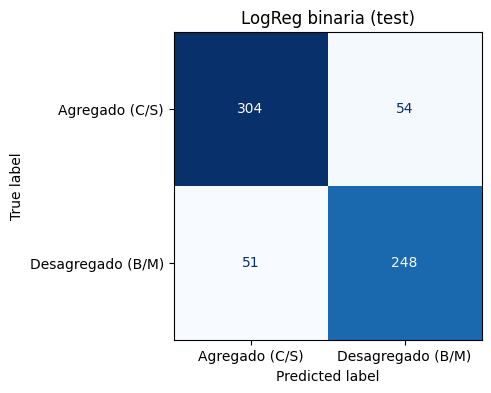

In [15]:
# 4.1 Reformulación binaria: ¿el registro viene desagregado (B: 6 períodos, M: 12) o agregado en 2 períodos (C, S)?
DESAGREGADOS = ['B', 'M']
yb_train = y_train.isin(DESAGREGADOS).astype(int)
yb_test = y_test.isin(DESAGREGADOS).astype(int)
print(f'Proporción de positivos (desagregado) en train: {yb_train.mean():.3f} | test: {yb_test.mean():.3f}')

modelos_bin = {
    'Baseline (más frecuente)': DummyClassifier(strategy='most_frequent'),
    'Baseline (estratificada)': DummyClassifier(strategy='stratified', random_state=RANDOM_STATE),
    'LogReg binaria': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
}
filas = []
for nombre, modelo in modelos_bin.items():
    s = cross_val_score(modelo, train[NUM_CLF], yb_train, cv=cv10, scoring='f1')
    modelo.fit(train[NUM_CLF], yb_train)
    pred = modelo.predict(test[NUM_CLF])
    proba = modelo.predict_proba(test[NUM_CLF])[:, 1]
    m = {'Accuracy': accuracy_score(yb_test, pred), 'Precision': precision_score(yb_test, pred, zero_division=0),
         'Recall': recall_score(yb_test, pred), 'F1': f1_score(yb_test, pred), 'ROC_AUC': roc_auc_score(yb_test, proba)}
    registrar('04', 'Binaria (B/M vs C/S)', nombre, m)
    filas.append({'Modelo': nombre, 'F1_CV10': s.mean(), 'Std_CV10': s.std(), **{f'{k}_test': v for k, v in m.items()}})
display(pd.DataFrame(filas).set_index('Modelo').round(4))

# ¿Cuánto rinde el modelo multiclase de la Act. 3 si colapsamos sus predicciones a la tarea binaria?
pred_multi_colapsada = pd.Series(logreg.predict(test[NUM_CLF])).isin(DESAGREGADOS).astype(int)
print(f'F1 binario usando la LogReg multiclase colapsada: {f1_score(yb_test, pred_multi_colapsada):.4f}')

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(yb_test, modelos_bin['LogReg binaria'].predict(test[NUM_CLF]),
                                        display_labels=['Agregado (C/S)', 'Desagregado (B/M)'],
                                        cmap='Blues', colorbar=False, ax=ax)
ax.set_title('LogReg binaria (test)')
ax.grid(False)
plt.show()

In [16]:
# 4.2 ¿Qué target numérico es genuino? Metros1 vs. Metros_Total.
# Si el target depende del formato (la duración del período), mide la forma de reportar y no la demanda.
filas = []
for target in ['Metros1', TARGET_REG]:
    for cols in [FEAT_REG, FEAT_REG + [TARGET_CLF]]:
        cats = [c for c in cols if c != 'Año']
        modelo = Pipeline([('prep', crear_prep_reg(cats)), ('modelo', LinearRegression())])
        s = cross_val_score(modelo, train[cols], train[target], cv=cv5_reg, scoring='r2')
        filas.append({'Target': target, 'Features': 'Año + IDs + Format_Reporte' if TARGET_CLF in cols else 'Año + IDs',
                      'R2_CV5': s.mean()})
display(pd.DataFrame(filas).pivot(index='Target', columns='Features', values='R2_CV5').round(3))

Features,Año + IDs,Año + IDs + Format_Reporte
Target,,
Metros1,0.318,0.636
Metros_Total,0.683,0.682


,RMSE_CV5,R2_CV5,MAE_test,MSE_test,RMSE_test,R2_test
Modelo,,,,,,
Baseline (media),2327.698,-0.003,1673.040,5437191.589,2331.779,-0.001
LinearRegression (Año + sucursal + tela),1305.479,0.683,843.449,1618778.038,1272.312,0.702
LinearRegression con interacción sucursal×tela,1213.162,0.727,664.748,1187589.062,1089.766,0.781


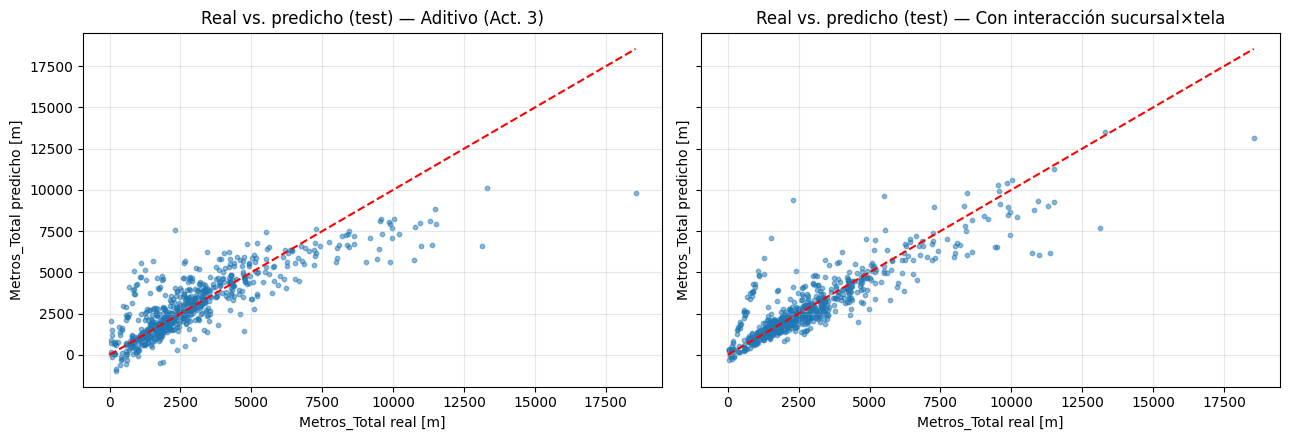

In [17]:
# 4.3 Modelo de regresión de la nueva tarea: interacción sucursal × tela (un efecto por par)
FEAT_REG_PAR = ['Año', 'Par_Suc_Tela']
fila_par, pred_par = evaluar_reg('LinearRegression con interacción sucursal×tela',
                                 Pipeline([('prep', crear_prep_reg(['Par_Suc_Tela'])), ('modelo', LinearRegression())]),
                                 FEAT_REG_PAR, '04')
display(pd.DataFrame([fila_base, fila_lin, fila_par]).set_index('Modelo').round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for a, (pred, titulo) in zip(ax, [(pred_lin, 'Aditivo (Act. 3)'), (pred_par, 'Con interacción sucursal×tela')]):
    a.scatter(yr_test, pred, s=10, alpha=0.5)
    a.plot([0, yr_test.max()], [0, yr_test.max()], 'r--')
    a.set(title=f'Real vs. predicho (test) — {titulo}', xlabel='Metros_Total real [m]', ylabel='Metros_Total predicho [m]')
plt.tight_layout()
plt.show()

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Reformulación binaria: "desagregado" (B o M, 6 o 12 períodos) contra "agregado" (C o S, 2 períodos).** No es una agrupación arbitraria: se apoya en la estructura observada en la EDA. En el negocio responde a si un registro sirve para analizar estacionalidad con detalle intra-anual. Quedan 45,6% de positivos, así que las clases siguen balanceadas.
- Usamos los mismos índices de train/test. Baselines correctas para una tarea binaria: clase mayoritaria (F1 = 0, porque nunca predice positivo) y estratificada. Métricas: F1, precisión, recall y ROC AUC. Comparamos además con la LogReg multiclase de la Act. 3 colapsada a dos clases.
- **Target numérico genuino:** comparamos `Metros1` y `Metros_Total` según cuánto dependen de `Format_Reporte`. Un target que cambia de escala con el formato no mide demanda sino la forma de reportar.
- **Modelo de la nueva tarea de regresión:** `LinearRegression` con la **interacción sucursal × tela** (una indicadora por par), porque la misma tela puede venderse distinto en cada sucursal.

**Interpretación de los resultados:**
- **Binaria:** la LogReg logra F1 CV10 = **0,819 ± 0,032** y en test F1 = 0,825, precisión 0,821, recall 0,829, **AUC 0,905**. Las baselines quedan en F1 0 (mayoritaria) y 0,465 (estratificada). Pero la LogReg multiclase colapsada da F1 = 0,828: **la tarea simplificada no resulta más fácil** para un modelo lineal, porque el grupo B/M mezcla cocientes ≈ 1,5 y ≈ 1.
- **Elección del target:** para `Metros1`, el R² CV pasa de **0,318 a 0,636** al agregar el formato, así que la mitad de lo que "explica" el modelo es la duración del período. Para `Metros_Total` queda **0,683 contra 0,682**: no depende del formato. Por eso es el target genuino.
- **Regresión con interacción:** RMSE CV5 1.213 m y R² CV5 0,727, contra 1.305 m y 0,683 del modelo aditivo. En test, RMSE **1.090 m** y R² **0,781** (aditivo: 1.272 m y 0,702; baseline: 2.332 m y 0). La nube real vs. predicho se acerca más a la diagonal.

**Pregunta de análisis:** ¿Qué información se pierde al simplificar la clasificación? ¿Cuándo convendría predecir una cantidad continua?
Al pasar a binario **se pierde la distinción entre B y M (6 contra 12 períodos) y entre C y S** (dos maneras distintas de repartir el año en 2 períodos). Justamente esa información hace falta para reconstruir las series o comparar magnitudes entre registros: saber que un registro es "desagregado" no alcanza para saber si `Metros1` es un mes o un bimestre. Además, en este caso la simplificación no mejoró el desempeño.

Conviene predecir una **cantidad continua** cuando la decisión depende de una magnitud y no de una categoría. Por ejemplo, planificar compras o stock de tela por sucursal requiere estimar cuántos metros se van a vender (`Metros_Total`). Discretizarlo en "alto/bajo" tiraría información y obligaría a fijar umbrales arbitrarios.

**Limitaciones o mejoras posibles:**
El modelo con interacción solo sirve para pares con historia: para un par nuevo cae a los efectos principales. El split aleatorio permite usar años posteriores del mismo par, así que para un pronóstico real habría que validar entrenando con años anteriores. La reformulación binaria podría evaluarse también con árboles.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 05 · Árboles de decisión · Parcial 1

**Qué se espera:** Compará árboles clasificadores con criterion=gini y entropy (max_depth=4 como inicio); explorá también un árbol regresor con profundidades distintas. Visualizá un árbol hasta profundidad 3 y compará importancias y métricas de las actividades 1–5.

**Evidencia a entregar:** Árboles, importancias, tabla acumulada; notebooks 01–05 ejecutables; tag `parcial-1`.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [18]:
# 5.1 Árboles clasificadores: gini vs. entropy con max_depth=4
arboles, filas = {}, []
for criterio in ['gini', 'entropy']:
    arbol = DecisionTreeClassifier(criterion=criterio, max_depth=4, random_state=RANDOM_STATE)
    s = cross_val_score(arbol, train[NUM_CLF], y_train, cv=cv10, scoring='f1_macro')
    arbol.fit(train[NUM_CLF], y_train)
    arboles[criterio] = arbol
    m = metricas_clf(y_test, arbol.predict(test[NUM_CLF]))
    registrar('05', 'Clasificación', f'Árbol {criterio} (max_depth=4)', m)
    filas.append({'Modelo': f'Árbol {criterio} (max_depth=4)', 'F1_macro_CV10': s.mean(), 'Std_CV10': s.std(),
                  **{f'{k}_test': v for k, v in m.items()}})
display(pd.DataFrame(filas).set_index('Modelo').round(4))
for criterio, arbol in arboles.items():
    var, umbral_raiz = NUM_CLF[arbol.tree_.feature[0]], arbol.tree_.threshold[0]
    extra = f'  (≈ Metros2/Metros1 = {np.exp(umbral_raiz):.2f})' if var == 'log_ratio_M2_M1' else \
            f'  (≈ Metros1 = {np.expm1(umbral_raiz):,.0f} m)' if var == 'log_M1' else ''
    print(f'Primera partición ({criterio}): {var} <= {umbral_raiz:.3f}{extra}')

,F1_macro_CV10,Std_CV10,Accuracy_test,F1_macro_test,F1_weighted_test
Modelo,,,,,
Árbol gini (max_depth=4),0.9389,0.0068,0.9346,0.9357,0.9345
Árbol entropy (max_depth=4),0.9382,0.0063,0.9346,0.9358,0.9344


Primera partición (gini): log_ratio_M2_M1 <= -0.202  (≈ Metros2/Metros1 = 0.82)
Primera partición (entropy): log_ratio_M2_M1 <= -0.202  (≈ Metros2/Metros1 = 0.82)


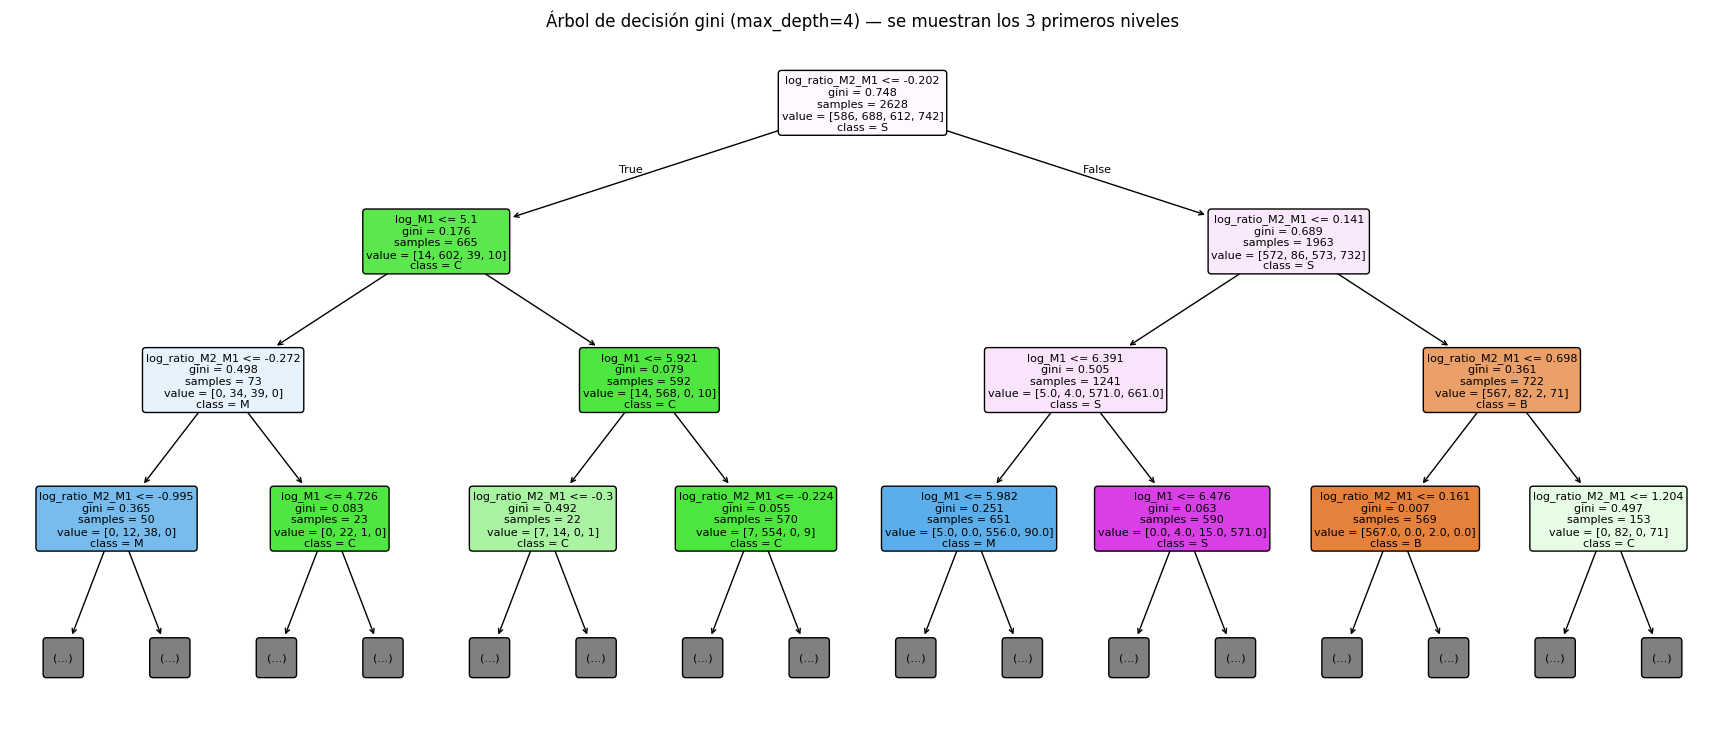

In [19]:
# 5.2 Visualización del árbol gini (3 primeros niveles)
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(arboles['gini'], max_depth=3, feature_names=NUM_CLF, class_names=list(arboles['gini'].classes_),
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title('Árbol de decisión gini (max_depth=4) — se muestran los 3 primeros niveles')
plt.show()

,Árbol gini,Árbol entropy,|coef| medio LogReg
Año,0.000,0.004,0.075
log_M1,0.281,0.218,1.171
log_ratio_M2_M1,0.719,0.778,1.059


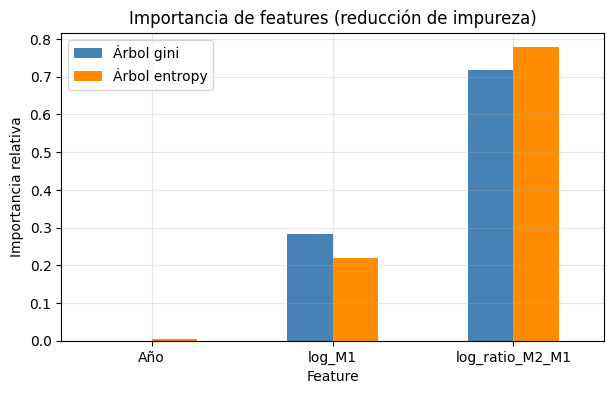

In [20]:
# 5.3 Importancias del árbol vs. magnitud de coeficientes de la LogReg (solo para comparar el orden)
imp = pd.DataFrame({f'Árbol {c}': a.feature_importances_ for c, a in arboles.items()}, index=NUM_CLF)
imp['|coef| medio LogReg'] = coefs.abs().mean().values
display(imp.round(3))
ax = imp[['Árbol gini', 'Árbol entropy']].plot.bar(rot=0, figsize=(7, 4), color=['steelblue', 'darkorange'])
ax.set(title='Importancia de features (reducción de impureza)', xlabel='Feature', ylabel='Importancia relativa')
plt.show()

,max_depth,R2_train,R2_CV5,Std_CV5
0,1,0.067,0.063,0.007
1,2,0.115,0.093,0.008
2,3,0.177,0.154,0.028
3,4,0.224,0.202,0.019
4,6,0.311,0.270,0.020
5,8,0.384,0.325,0.027
6,10,0.451,0.353,0.040
7,15,0.637,0.383,0.052
8,None,1.000,0.208,0.150


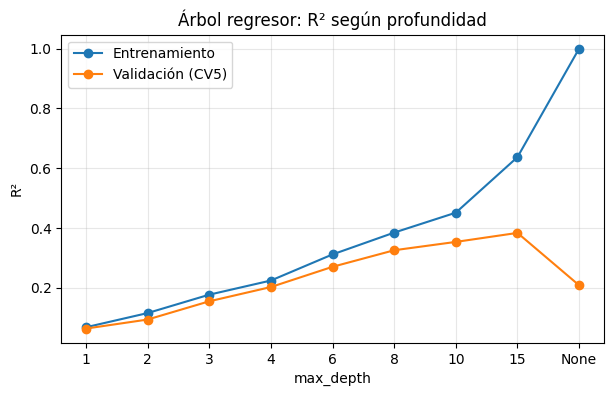

Profundidad elegida por CV: 15


In [21]:
# 5.4 Árbol regresor para Metros_Total con distintas profundidades (selección por CV, no por test)
profundidades = [1, 2, 3, 4, 6, 8, 10, 15, None]
filas = []
for d in profundidades:
    arbol_r = Pipeline([('prep', crear_prep_reg()), ('modelo', DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE))])
    r = cross_validate(arbol_r, train[FEAT_REG], yr_train, cv=cv5_reg, scoring='r2', return_train_score=True)
    filas.append({'max_depth': str(d), 'R2_train': r['train_score'].mean(),
                  'R2_CV5': r['test_score'].mean(), 'Std_CV5': r['test_score'].std()})
tabla_dr = pd.DataFrame(filas)
display(tabla_dr.round(3))
mejor_d = profundidades[tabla_dr['R2_CV5'].idxmax()]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tabla_dr['max_depth'], tabla_dr['R2_train'], 'o-', label='Entrenamiento')
ax.plot(tabla_dr['max_depth'], tabla_dr['R2_CV5'], 'o-', label='Validación (CV5)')
ax.set(title='Árbol regresor: R² según profundidad', xlabel='max_depth', ylabel='R²')
ax.legend()
plt.show()

fila_arbol_r, _ = evaluar_reg(f'Árbol regresor (max_depth={mejor_d})',
                              Pipeline([('prep', crear_prep_reg()),
                                        ('modelo', DecisionTreeRegressor(max_depth=mejor_d, random_state=RANDOM_STATE))]),
                              FEAT_REG, '05')
print(f'Profundidad elegida por CV: {mejor_d}')

In [22]:
# 5.5 Tabla acumulada de las actividades 1 a 5 (métricas de test históricas)
for tarea in ['Clasificación', 'Binaria (B/M vs C/S)', 'Regresión']:
    print(tarea)
    display(tabla_historica(tarea).round(4))

Clasificación


,Actividad,Accuracy,F1_macro,F1_weighted
Modelo,,,,
Baseline (más frecuente),01-02,0.2831,0.1103,0.1249
"LogReg (Año, Metros1, Metros2 crudas)",03,0.7336,0.7296,0.7356
"LogReg (Año, log_M1, log_ratio)",03,0.7686,0.7686,0.7670
Árbol gini (max_depth=4),05,0.9346,0.9357,0.9345
Árbol entropy (max_depth=4),05,0.9346,0.9358,0.9344


Binaria (B/M vs C/S)


,Actividad,Accuracy,Precision,Recall,F1,ROC_AUC
Modelo,,,,,,
Baseline (más frecuente),04,0.5449,0.0000,0.0000,0.0000,0.5000
Baseline (estratificada),04,0.5129,0.4649,0.4649,0.4649,0.5090
LogReg binaria,04,0.8402,0.8212,0.8294,0.8253,0.9048


Regresión


,Actividad,MAE,MSE,RMSE,R2
Modelo,,,,,
Baseline (media),01-02,1673.0396,5.437192e+06,2331.7786,-0.0006
LinearRegression (Año + sucursal + tela),03,843.4495,1.618778e+06,1272.3121,0.7021
LinearRegression con interacción sucursal×tela,04,664.7477,1.187589e+06,1089.7656,0.7815
Árbol regresor (max_depth=15),05,1098.8819,2.870605e+06,1694.2859,0.4718


### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- Árboles de clasificación con `criterion='gini'` y `'entropy'` y `max_depth=4`, sobre las tres features numéricas. No se escalan porque los árboles solo usan umbrales.
- Evaluamos con CV10 sobre train (para decidir) y reportamos test como métrica histórica.
- Para la regresión, un `DecisionTreeRegressor` sobre `Metros_Total` (con `Año` + one-hot de sucursal y tela), con profundidades de 1 a 15 y sin límite. La profundidad se elige por CV5, nunca por test.
- La tabla acumulada reúne todas las métricas de test de las actividades 1 a 5.

**Interpretación de los resultados:**
- **Gini:** F1 CV10 = **0,939 ± 0,007**, test 0,936. **Entropy:** 0,938 ± 0,006, test 0,936. Son prácticamente iguales, con la misma raíz y casi la misma estructura. Frente a la LogReg (0,760) hay un salto de casi 18 puntos, porque el árbol arma **intervalos** sobre el cociente y aísla la banda intermedia.
- **Lectura del árbol:** la raíz separa `log_ratio ≤ −0,202` (Metros2/Metros1 ≤ 0,82), donde 602 de 665 registros son C. En la rama derecha, `log_ratio ≤ 0,141` (cociente ≤ 1,15) separa B (567 de 569 casos con cociente mayor) de M y S. Después, `log_M1 ≤ 6,39` (Metros1 ≈ 595 m) separa M (valores chicos, mensuales) de S (valores grandes).
- **Importancias:** `log_ratio` 0,72 (gini) y 0,78 (entropy); `log_M1` 0,28 y 0,22; `Año` ≈ 0.
- **Árbol regresor:** el R² de CV crece hasta 0,383 (profundidad 15), con desvío alto (0,052) y train 0,64. Sin límite, train llega a 1,00 y CV cae a 0,21 (sobreajuste). En test, R² = 0,472, muy por debajo de la regresión lineal (0,70 aditiva, 0,78 con interacción): con indicadoras, cada partición aísla una sola sucursal o tela, y un árbol necesita muchísimos cortes para reproducir efectos aditivos.

**Pregunta de análisis:** ¿Qué variable produce la primera partición? ¿Coinciden las importancias con el modelo lineal?
La primera partición es **`log_ratio_M2_M1 ≤ −0,202`**, es decir Metros2/Metros1 ≤ 0,82, y aísla casi toda la clase C. Las importancias **coinciden en lo cualitativo** con el modelo lineal: las dos features de metros son las que importan y `Año` no aporta. Difieren en la jerarquía. En la LogReg, `log_M1` y `log_ratio` tienen magnitudes parecidas (|coef| medio 1,17 y 1,06); en el árbol, el cociente domina (0,72). Pasa porque el cociente se relaciona con las clases de forma **no monótona** (C < S ≈ M < B): el árbol la aprovecha con cortes sucesivos y la LogReg no. Además, las dos medidas no son comparables directamente: una es el efecto lineal en log-odds y la otra la reducción de impureza.

**Limitaciones o mejoras posibles:**
La importancia por impureza puede sesgarse y no informa la dirección del efecto; la importancia por permutación sería un buen complemento. Un árbol individual es inestable ante cambios en los datos. Para la regresión, los árboles con indicadoras no son una buena familia de modelos y convendría un modelo lineal regularizado (Act. 10) o boosting.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 06 · Ensembles: Random Forest y XGBoost

**Qué se espera:** Entrená Random Forest (100 árboles) y XGBoost (100 estimadores, learning_rate=0.1, max_depth=3) en la tarea principal. Compará ambos con el árbol individual y visualizá importancias de features.

**Evidencia a entregar:** Tabla comparativa y gráficos de importancias.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [23]:
# 6.1 Random Forest y XGBoost con los hiperparámetros del enunciado vs. el árbol individual
modelos_ens = {
    'Árbol gini (max_depth=4)': DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=RANDOM_STATE),
    'Random Forest (100 árboles)': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    # XGBoost exige etiquetas enteras: el envoltorio codifica y decodifica 'B', 'C', 'M', 'S'
    'XGBoost (100, lr=0.1, depth=3)': ClasificadorEtiquetado(XGBClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE, n_jobs=-1)),
}
filas, ajustados = [], {}
for nombre, modelo in modelos_ens.items():
    t0 = time.perf_counter(); modelo.fit(train[NUM_CLF], y_train); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = modelo.predict(test[NUM_CLF]); t_pred = time.perf_counter() - t0
    m = metricas_clf(y_test, pred)
    if not nombre.startswith('Árbol'):
        registrar('06', 'Clasificación', nombre, m)
    ajustados[nombre] = modelo
    filas.append({'Modelo': nombre, **{f'{k}_test': v for k, v in m.items()},
                  'Tiempo ajuste [s]': t_fit, 'Tiempo predicción [ms]': t_pred * 1000})
filas.insert(0, {'Modelo': 'Baseline (más frecuente)', **{f'{k}_test': v for k, v in metricas_clf(y_test, pred_base_clf).items()}})
display(pd.DataFrame(filas).set_index('Modelo').round(4))

f1_clase = pd.DataFrame({n: f1_score(y_test, mo.predict(test[NUM_CLF]), average=None, labels=CLASES)
                         for n, mo in ajustados.items()}, index=CLASES)
print('F1 por clase (test):')
display(f1_clase.round(3))

,Accuracy_test,F1_macro_test,F1_weighted_test,Tiempo ajuste [s],Tiempo predicción [ms]
Modelo,,,,,
Baseline (más frecuente),0.2831,0.1103,0.1249,NaN,NaN
Árbol gini (max_depth=4),0.9346,0.9357,0.9345,0.0113,2.4870
Random Forest (100 árboles),0.9422,0.9428,0.9421,0.3094,46.4876
"XGBoost (100, lr=0.1, depth=3)",0.9513,0.9519,0.9513,0.2993,8.5086


F1 por clase (test):


,Árbol gini (max_depth=4),Random Forest (100 árboles),"XGBoost (100, lr=0.1, depth=3)"
B,0.979,0.979,0.979
C,0.983,0.980,0.983
M,0.886,0.897,0.918
S,0.895,0.915,0.928


,Árbol gini (max_depth=4),Random Forest (100 árboles),"XGBoost (100, lr=0.1, depth=3)"
Año,0.000,0.031,0.055
log_M1,0.281,0.305,0.280
log_ratio_M2_M1,0.719,0.664,0.665


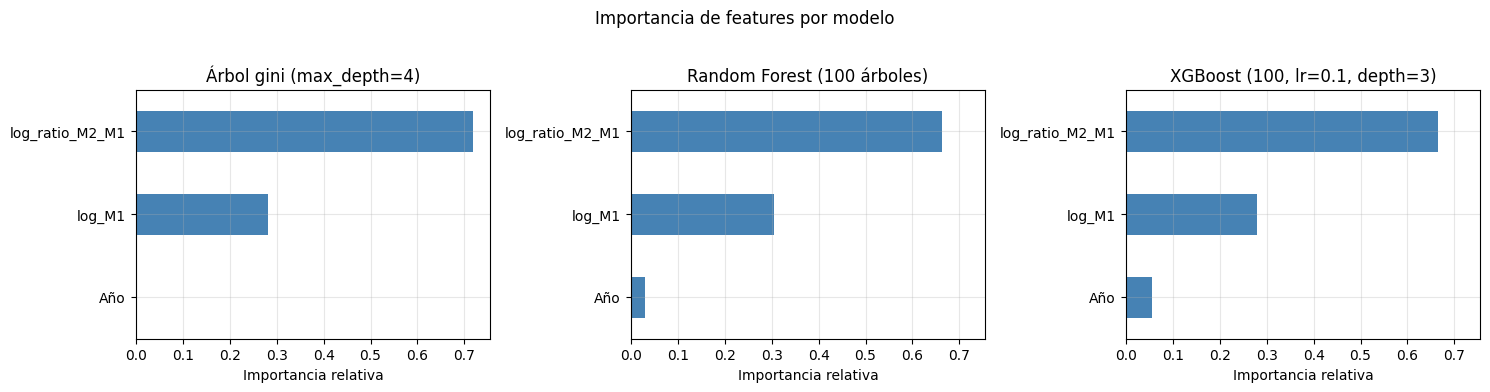

In [24]:
# 6.2 Importancias de features de los tres modelos
imp_ens = pd.DataFrame({n: mo.feature_importances_ for n, mo in ajustados.items()}, index=NUM_CLF)
display(imp_ens.round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True)
for a, col in zip(ax, imp_ens.columns):
    imp_ens[col].sort_values().plot.barh(ax=a, color='steelblue')
    a.set(title=col, xlabel='Importancia relativa')
plt.suptitle('Importancia de features por modelo', y=1.02)
plt.tight_layout()
plt.show()

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- `RandomForestClassifier(n_estimators=100)` y `XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3)`, como pide el enunciado, con las mismas tres features y `random_state=42`.
- XGBoost necesita etiquetas enteras, así que usamos un envoltorio propio (`ClasificadorEtiquetado`, en `src/ortelana_ml.py`) que codifica y decodifica 'B', 'C', 'M', 'S'. El mismo envoltorio permite después usar XGBoost dentro del pipeline productivo.
- Medimos los tiempos de ajuste y de predicción y el F1 por clase. La comparación con CV queda para la Act. 7.

**Interpretación de los resultados:**
- **F1 macro en test:** baseline 0,110, árbol 0,936, Random Forest 0,943, **XGBoost 0,952**.
- **Por clase:** B y C ya estaban casi resueltas por el árbol (~0,98). La mejora de los ensambles está en **M (0,886 → 0,918)** y **S (0,895 → 0,928)**, las dos clases con cociente ≈ 1 que solo se separan por escala. Ahí combinar muchos cortes suaviza la frontera.
- **Importancias:** el orden es el mismo en los tres modelos (`log_ratio` ≈ 0,66–0,72, `log_M1` ≈ 0,28–0,31). Los ensambles le asignan algo de peso a `Año` (0,03–0,06), que probablemente sea ruido aprovechado en cortes menores.

**Pregunta de análisis:** ¿El ensamble mejora la baseline y el árbol? ¿Qué sacrificios de interpretación o costo computacional observás?
**Sí mejoran a la baseline** (de 0,11 a 0,94–0,95) **y al árbol**, aunque de forma moderada: +0,7 puntos el RF y +1,6 el XGBoost en test. Con un solo split no alcanza para afirmar que la diferencia es real, y por eso la Act. 7 la contrasta con CV.

**Sacrificios:** el árbol de profundidad 4 se lee completo en una figura y se puede explicar como reglas ("si el cociente es menor a 0,82, es C"). Un bosque de 100 árboles profundos o 100 árboles de boosting secuenciales no se pueden leer, y solo quedan herramientas indirectas como las importancias. **Costo:** el ajuste pasa de ~0,01 s a ~0,2–0,35 s (20 a 30 veces más) y la predicción de 657 filas de ~3 ms a ~50–60 ms (RF) o ~7–9 ms (XGB). Los valores exactos cambian un poco entre ejecuciones, pero en términos absolutos es poco para este volumen. El RF también pesa más en disco.

**Limitaciones o mejoras posibles:**
Los hiperparámetros están fijados por la consigna y no optimizados. Las importancias por impureza tienen sesgos. Sumar importancia por permutación o valores SHAP mejoraría la interpretación de los ensambles.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 07 · Validación cruzada y estabilidad

**Qué se espera:** Aplicá StratifiedKFold de 10 particiones a los tres modelos de árbol sobre entrenamiento. Mostrá los diez scores, media y desvío estándar; compará la estabilidad entre modelos.

**Evidencia a entregar:** Tabla de media ± desviación estándar de CV.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [25]:
# 7.1 StratifiedKFold de 10 particiones sobre train para los tres modelos de árbol
scores_cv = {nombre: cross_val_score(clone(modelo), train[NUM_CLF], y_train, cv=cv10, scoring='f1_macro', n_jobs=-1)
             for nombre, modelo in modelos_ens.items()}
tabla_folds = pd.DataFrame(scores_cv, index=[f'Fold {i}' for i in range(1, 11)])
display(tabla_folds.round(4))

resumen_cv = pd.DataFrame({'F1_macro_CV10_media': tabla_folds.mean(), 'Std_CV10': tabla_folds.std(ddof=0),
                           'Mín': tabla_folds.min(), 'Máx': tabla_folds.max(),
                           'F1_macro_test (Act. 6)': [metricas_clf(y_test, ajustados[n].predict(test[NUM_CLF]))['F1_macro']
                                                      for n in tabla_folds.columns]})
resumen_cv['Media ± std'] = [f'{a:.4f} ± {b:.4f}' for a, b in zip(resumen_cv['F1_macro_CV10_media'], resumen_cv['Std_CV10'])]
display(resumen_cv.round(4))

,Árbol gini (max_depth=4),Random Forest (100 árboles),"XGBoost (100, lr=0.1, depth=3)"
Fold 1,0.9296,0.9259,0.9411
Fold 2,0.9373,0.9364,0.9434
Fold 3,0.9356,0.9465,0.9505
Fold 4,0.9291,0.9437,0.9365
Fold 5,0.9443,0.9369,0.9546
Fold 6,0.9378,0.9522,0.9523
Fold 7,0.9508,0.9428,0.9509
Fold 8,0.9398,0.9463,0.9435
Fold 9,0.9483,0.9516,0.9589
Fold 10,0.9362,0.9429,0.9393


,F1_macro_CV10_media,Std_CV10,Mín,Máx,F1_macro_test (Act. 6),Media ± std
Árbol gini (max_depth=4),0.9389,0.0068,0.9291,0.9508,0.9357,0.9389 ± 0.0068
Random Forest (100 árboles),0.9425,0.0074,0.9259,0.9522,0.9428,0.9425 ± 0.0074
"XGBoost (100, lr=0.1, depth=3)",0.9471,0.0070,0.9365,0.9589,0.9519,0.9471 ± 0.0070


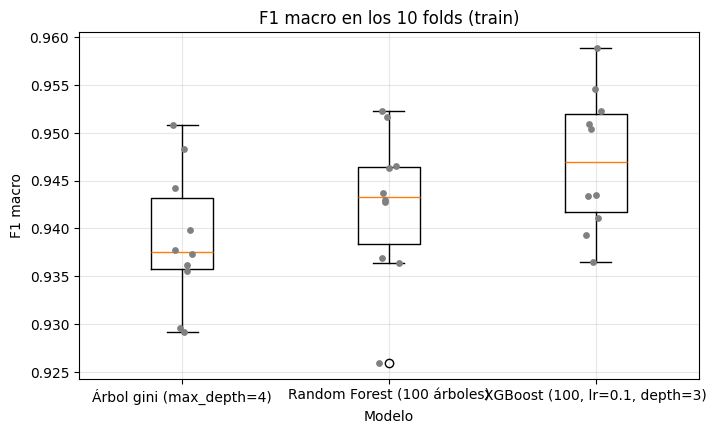

In [26]:
# 7.2 Estabilidad entre folds
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([tabla_folds[c] for c in tabla_folds.columns], tick_labels=tabla_folds.columns)
for i, c in enumerate(tabla_folds.columns, start=1):
    ax.scatter(np.full(10, i) + np.random.uniform(-0.05, 0.05, 10), tabla_folds[c], s=15, color='gray', zorder=3)
ax.set(title='F1 macro en los 10 folds (train)', ylabel='F1 macro', xlabel='Modelo')
plt.show()

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- `StratifiedKFold(n_splits=10, shuffle=True, random_state=42)` **solo sobre train**, con **los mismos folds para los tres modelos**. Eso permite una comparación pareada fold a fold.
- Reportamos los 10 scores, la media, el desvío, el mínimo y el máximo, y los ponemos al lado del F1 de test de la Act. 6.

**Interpretación de los resultados:**
- **Árbol gini:** 0,9389 ± 0,0068. **Random Forest:** 0,9425 ± 0,0074. **XGBoost:** 0,9471 ± 0,0070.
- Los tres desvíos rondan 0,007, muy por debajo de 0,02, así que los tres son **estables** y la variación entre folds es parecida.
- Fold a fold, XGBoost supera al árbol en los **10 folds** y al RF en **7 de 10**. La ventaja sobre el árbol es consistente; la ventaja sobre el RF es chica (0,5 puntos, menos que un desvío).
- Los valores de test (0,936, 0,943 y 0,952) caen dentro del rango [mín, máx] de cada modelo en CV. No hay señales de que el test sea "raro".

**Pregunta de análisis:** ¿Qué significa un desvío superior a 0,02? ¿Cambiaría tu elección si solo hubieras mirado test?
Un desvío **mayor a 0,02** significa que el F1 cambia unos ±2 puntos según qué filas caigan en validación: el modelo es sensible a la muestra, sea por pocos datos, por un modelo inestable (como un árbol profundo) o por subgrupos difíciles que no se reparten igual. En la práctica, diferencias entre modelos menores a ese desvío **no se pueden distinguir del ruido**.

**Si solo hubiéramos mirado test**, en este caso el orden habría sido el mismo (XGB > RF > árbol), pero por azar. Un único split de 657 filas tiene un intervalo de confianza de unos ±1,6 puntos (Act. 15), comparable con la distancia entre modelos. La Act. 15 muestra un caso concreto: el XGBoost con los hiperparámetros de la consigna tuvo un test histórico mejor (0,952) que el XGBoost ajustado (0,949), aunque este último es mejor en CV. Elegir por test habría sido elegir por ruido y, además, habría sesgado la evaluación final.

**Limitaciones o mejoras posibles:**
Los folds comparten datos de entrenamiento, así que el desvío de CV subestima la incertidumbre real. Además, la CV aleatoria no controla la dependencia por par sucursal-tela; eso se aborda con la validación agrupada de la Act. 9. Repetir la CV con varias semillas (`RepeatedStratifiedKFold`) daría una estimación más firme.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 08 · Diagnóstico de generalización

**Qué se espera:** Construí curvas de aprendizaje para árbol y ensamble; explorá train y CV al variar max_depth de 1 a 15 en el árbol. Proponé dos medidas para corregir el diagnóstico.

**Evidencia a entregar:** Curvas, diagnóstico de overfitting/underfitting y propuestas.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


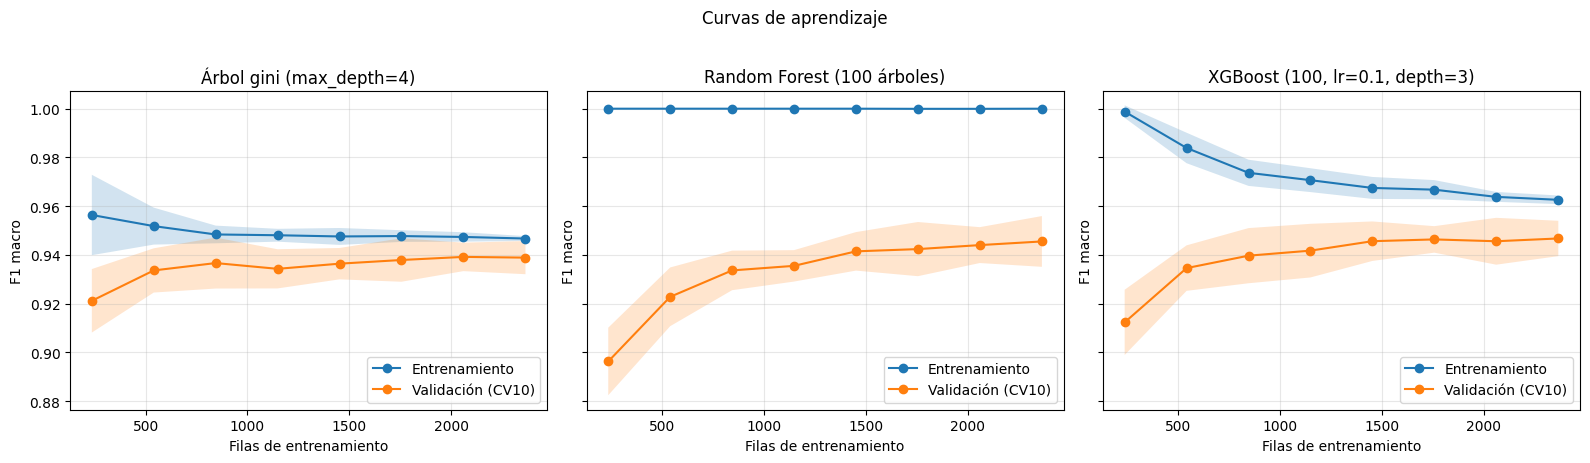

,F1_train (n máx.),F1_CV (n máx.),Brecha,F1_CV con 10% de datos
Modelo,,,,
Árbol gini (max_depth=4),0.9467,0.9389,0.0078,0.9212
Random Forest (100 árboles),1.0000,0.9455,0.0545,0.8963
"XGBoost (100, lr=0.1, depth=3)",0.9626,0.9468,0.0159,0.9123


In [27]:
# 8.1 Curvas de aprendizaje: árbol individual y ensambles
tamanos = np.linspace(0.1, 1.0, 8)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
brechas = []
for a, (nombre, modelo) in zip(ax, modelos_ens.items()):
    n, tr_s, va_s = learning_curve(clone(modelo), train[NUM_CLF], y_train, cv=cv10, train_sizes=tamanos,
                                   scoring='f1_macro', n_jobs=-1, shuffle=True, random_state=RANDOM_STATE)
    for scores, etiqueta in [(tr_s, 'Entrenamiento'), (va_s, 'Validación (CV10)')]:
        a.plot(n, scores.mean(1), 'o-', label=etiqueta)
        a.fill_between(n, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1), alpha=0.2)
    a.set(title=nombre, xlabel='Filas de entrenamiento', ylabel='F1 macro')
    a.legend(loc='lower right')
    brechas.append({'Modelo': nombre, 'F1_train (n máx.)': tr_s[-1].mean(), 'F1_CV (n máx.)': va_s[-1].mean(),
                    'Brecha': tr_s[-1].mean() - va_s[-1].mean(), 'F1_CV con 10% de datos': va_s[0].mean()})
plt.suptitle('Curvas de aprendizaje', y=1.02)
plt.tight_layout()
plt.show()
display(pd.DataFrame(brechas).set_index('Modelo').round(4))

max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
F1_train,0.3578,0.6338,0.9167,0.9468,0.9531,0.9595,0.9664,0.9732,0.9790,0.9829,0.9867,0.9890,0.9912,0.9930,0.9944
F1_CV10,0.3563,0.6319,0.9107,0.9389,0.9382,0.9371,0.9363,0.9367,0.9340,0.9357,0.9335,0.9306,0.9295,0.9291,0.9272
Std_CV10,0.0105,0.0207,0.0100,0.0068,0.0110,0.0098,0.0098,0.0125,0.0104,0.0131,0.0119,0.0108,0.0067,0.0102,0.0088
Brecha,0.0016,0.0019,0.0061,0.0080,0.0149,0.0224,0.0302,0.0364,0.0450,0.0473,0.0533,0.0584,0.0616,0.0639,0.0672


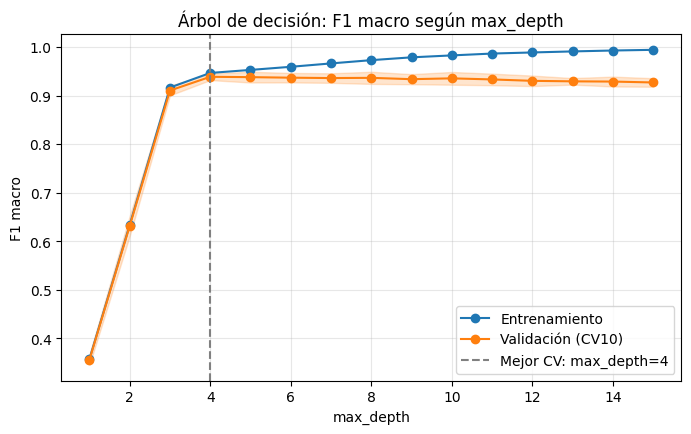

In [28]:
# 8.2 Curva de validación del árbol: max_depth de 1 a 15
depths = np.arange(1, 16)
tr_s, va_s = validation_curve(DecisionTreeClassifier(random_state=RANDOM_STATE), train[NUM_CLF], y_train,
                              param_name='max_depth', param_range=depths, cv=cv10, scoring='f1_macro', n_jobs=-1)
tabla_vc = pd.DataFrame({'max_depth': depths, 'F1_train': tr_s.mean(1), 'F1_CV10': va_s.mean(1),
                         'Std_CV10': va_s.std(1)})
tabla_vc['Brecha'] = tabla_vc['F1_train'] - tabla_vc['F1_CV10']
display(tabla_vc.round(4).set_index('max_depth').T)
d_opt = int(tabla_vc.loc[tabla_vc['F1_CV10'].idxmax(), 'max_depth'])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(depths, tabla_vc['F1_train'], 'o-', label='Entrenamiento')
ax.plot(depths, tabla_vc['F1_CV10'], 'o-', label='Validación (CV10)')
ax.fill_between(depths, va_s.mean(1) - va_s.std(1), va_s.mean(1) + va_s.std(1), alpha=0.2, color='C1')
ax.axvline(d_opt, color='gray', ls='--', label=f'Mejor CV: max_depth={d_opt}')
ax.set(title='Árbol de decisión: F1 macro según max_depth', xlabel='max_depth', ylabel='F1 macro')
ax.legend()
plt.show()

In [29]:
# 8.3 Medidas correctivas evaluadas solo con CV sobre train
# (1) limitar la complejidad del árbol (profundidad elegida por CV + mínimo de filas por hoja)
# (2) regularizar el Random Forest (hojas mínimas y profundidad máxima) para cerrar la brecha
correcciones = {
    'Árbol max_depth=4 (inicial)': DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    'Árbol sin límite': DecisionTreeClassifier(random_state=RANDOM_STATE),
    f'Árbol max_depth={d_opt}, min_samples_leaf=10': DecisionTreeClassifier(max_depth=d_opt, min_samples_leaf=10, random_state=RANDOM_STATE),
    'Random Forest sin restricciones': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'Random Forest min_samples_leaf=5, max_depth=10': RandomForestClassifier(n_estimators=100, min_samples_leaf=5, max_depth=10,
                                                                             random_state=RANDOM_STATE, n_jobs=-1),
}
filas = []
for nombre, modelo in correcciones.items():
    r = cross_validate(modelo, train[NUM_CLF], y_train, cv=cv10, scoring='f1_macro', return_train_score=True, n_jobs=-1)
    filas.append({'Modelo': nombre, 'F1_train': r['train_score'].mean(), 'F1_CV10': r['test_score'].mean(),
                  'Std_CV10': r['test_score'].std(), 'Brecha': r['train_score'].mean() - r['test_score'].mean()})
display(pd.DataFrame(filas).set_index('Modelo').round(4))

,F1_train,F1_CV10,Std_CV10,Brecha
Modelo,,,,
Árbol max_depth=4 (inicial),0.9468,0.9389,0.0068,0.0080
Árbol sin límite,1.0000,0.9270,0.0120,0.0730
"Árbol max_depth=4, min_samples_leaf=10",0.9448,0.9385,0.0051,0.0063
Random Forest sin restricciones,1.0000,0.9425,0.0074,0.0575
"Random Forest min_samples_leaf=5, max_depth=10",0.9624,0.9413,0.0083,0.0211


### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- Curvas de aprendizaje (`learning_curve`) con 8 tamaños del 10% al 100% de train y CV10, para el árbol y para los dos ensambles.
- Curva de validación (`validation_curve`) del árbol con `max_depth` de 1 a 15.
- Las dos medidas correctivas se evalúan **también con CV sobre train**, no con test.

**Interpretación de los resultados:**
- **Curvas de aprendizaje:** el árbol (profundidad 4) termina con train 0,947 y CV 0,939 (brecha 0,008): un ajuste equilibrado con algo de sesgo. El **Random Forest llega a train = 1,000 contra CV 0,946 (brecha 0,055)**: memoriza el entrenamiento, aunque la validación sigue siendo buena gracias al promediado y todavía sube con más datos (de 0,896 con 10% a 0,946). XGBoost queda en el medio (0,963 contra 0,947, brecha 0,016).
- **Curva de validación:** con profundidad 1 el F1 es 0,356 y con 2 es 0,632 (**underfitting**, sin brecha). Con 3 sube a 0,911 y **el máximo de CV está en 4 (0,939)**. Desde ahí el CV baja lentamente hasta 0,927 en 15, mientras train sube hasta 0,994 y la brecha crece de 0,008 a 0,067 (**overfitting**).
- **Medidas correctivas evaluadas:**
  1. *Limitar la complejidad del árbol:* profundidad 4 elegida por CV más `min_samples_leaf=10` da 0,9385 con el desvío más bajo (0,0051) y brecha 0,006. El árbol sin límite da 0,927 con brecha 0,073.
  2. *Regularizar el Random Forest* (`min_samples_leaf=5`, `max_depth=10`): la brecha baja de 0,058 a 0,021 y el CV prácticamente no cambia (0,9413 contra 0,9425). El modelo es más simple y generaliza igual.

**Pregunta de análisis:** ¿Dónde se abre una brecha entre entrenamiento y validación? ¿Más complejidad siempre ayuda?
En el árbol, la brecha **se abre a partir de `max_depth` 5–6** (pasa de 0,015 a 0,022) y crece sin parar. En el RF sin restricciones está presente desde el principio porque sus árboles crecen hasta hojas puras. **Más complejidad no siempre ayuda:** el CV del árbol alcanza su máximo en profundidad 4 y empeora con más profundidad. En el RF, frenar el crecimiento achica la brecha sin pérdida de validación. Agregar complejidad solo sirve mientras reduce sesgo. Pasado ese punto, el modelo empieza a aprender el ruido de train.

**Limitaciones o mejoras posibles:**
Además de estas dos medidas, se puede sumar más datos (las curvas de los ensambles siguen subiendo levemente) y mejorar las features (por ejemplo, información de más períodos sin caer en el proxy). El diagnóstico se basa en CV aleatoria; con validación agrupada por par, las brechas podrían ser algo mayores.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 09 · Pipeline y ColumnTransformer

**Qué se espera:** Diseñá tratamiento numérico (imputación + escalado) y categórico (imputación + OneHotEncoder) dentro de ColumnTransformer y Pipeline. Validá por CV y probá una predicción con faltantes.

**Evidencia a entregar:** Pipeline completo, CV sin fuga y predicción de prueba con NaN.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [30]:
# 9.1 Pipeline completo: features fila a fila -> ColumnTransformer (num + cat) -> modelo
def crear_preprocesador(usar_ids=True, escalar=True):
    pasos_num = [('imputar', SimpleImputer(strategy='median'))]
    if escalar:
        pasos_num.append(('escalar', StandardScaler()))
    transformadores = [('num', Pipeline(pasos_num), NUM_CLF)]
    if usar_ids:
        transformadores.append(('cat', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                                                 ('onehot', OneHotEncoder(handle_unknown='ignore'))]), CAT_ID))
    return ColumnTransformer(transformadores)

def crear_pipeline_clf(modelo, usar_ids=True, escalar=True):
    return Pipeline([('features', FunctionTransformer(agregar_features)),
                     ('prep', crear_preprocesador(usar_ids, escalar)),
                     ('modelo', modelo)])

# Desde acá los modelos reciben las columnas crudas: todo el preprocesamiento ocurre dentro del pipeline
X_train, X_test = train[COLUMNAS_ENTRADA], test[COLUMNAS_ENTRADA]
rf_base = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
display(crear_pipeline_clf(rf_base))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function agr...0019C6299B060>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary 

In [31]:
# 9.2 Validación cruzada sin fuga. Además de StratifiedKFold, se valida agrupando por par sucursal-tela
# (StratifiedGroupKFold): mide el desempeño sobre pares que el modelo nunca vio.
cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grupos_train = train['Par_Suc_Tela']
modelos_p = {'LogReg': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), 'Random Forest': rf_base}
filas = []
for nombre, modelo in modelos_p.items():
    for usar_ids in [False, True]:
        pipe = crear_pipeline_clf(clone(modelo), usar_ids=usar_ids)
        s = cross_val_score(pipe, X_train, y_train, cv=cv10, scoring='f1_macro', n_jobs=-1)
        g = cross_val_score(pipe, X_train, y_train, cv=cv_grupos, groups=grupos_train, scoring='f1_macro', n_jobs=-1)
        filas.append({'Modelo': nombre, 'Incluye IDs one-hot': usar_ids, 'F1_CV10 (aleatoria)': s.mean(),
                      'Std_CV10': s.std(), 'F1_CV por grupos (pares no vistos)': g.mean(),
                      'Caída al cambiar de esquema': s.mean() - g.mean()})
display(pd.DataFrame(filas).set_index(['Modelo', 'Incluye IDs one-hot']).round(4))

F1_CV10 (aleatoria)  Std_CV10  \
Modelo        Incluye IDs one-hot                                  
LogReg        False                             0.7600    0.0207   
              True                              0.8364    0.0115   
Random Forest False                             0.9425    0.0082   
              True                              0.9820    0.0084   

                                   F1_CV por grupos (pares no vistos)  \
Modelo        Incluye IDs one-hot                                       
LogReg        False                                            0.7577   
              True                                             0.7096   
Random Forest False                                            0.9340   
              True                                             0.9169   

                                   Caída al cambiar de esquema  
Modelo        Incluye IDs one-hot                               
LogReg        False                                     0.0023  
              True                                      0.1268  
Random Forest False                                     0.0085  
              True                                      0.0651

In [32]:
# 9.3 Ajuste final de los pipelines de Random Forest y predicción de prueba con faltantes
pipe_rf_ids = crear_pipeline_clf(clone(rf_base), usar_ids=True).fit(X_train, y_train)
pipe_rf_sin = crear_pipeline_clf(clone(rf_base), usar_ids=False).fit(X_train, y_train)
registrar('09', 'Clasificación', 'Random Forest + IDs one-hot (pipeline)', metricas_clf(y_test, pipe_rf_ids.predict(X_test)))
registrar('09', 'Clasificación', 'Random Forest sin IDs (pipeline)', metricas_clf(y_test, pipe_rf_sin.predict(X_test)))

casos_nan = pd.DataFrame({
    'Sucursal_ID': [3, np.nan, 5, 12],
    'Año': [2024, 2025, np.nan, 2026],
    'Tela_ID': ['TELA-004', 'TELA-010', np.nan, 'TELA-999'],   # TELA-999 no existe en train
    'Metros1': [250.0, np.nan, 1800.0, 160.0],
    'Metros2': [370.0, 1300.0, np.nan, 158.0],
})
print('Transformación del pipeline (primeras columnas tras imputar y escalar):')
display(pd.DataFrame(pipe_rf_sin[:-1].transform(casos_nan), columns=NUM_CLF).round(3))
salida = casos_nan.copy()
salida['pred (con IDs)'] = pipe_rf_ids.predict(casos_nan)
salida['pred (sin IDs)'] = pipe_rf_sin.predict(casos_nan)
proba = pd.DataFrame(pipe_rf_sin.predict_proba(casos_nan), columns=[f'P({c})' for c in pipe_rf_sin.classes_])
display(pd.concat([salida, proba.round(2)], axis=1))

Transformación del pipeline (primeras columnas tras imputar y escalar):


,Año,log_M1,log_ratio_M2_M1
0,1.227,-0.474,0.756
1,1.576,0.093,-0.121
2,-0.169,0.974,-0.121
3,1.925,-0.800,-0.186


,Sucursal_ID,Año,Tela_ID,Metros1,Metros2,pred (con IDs),pred (sin IDs),P(B),P(C),P(M),P(S)
0,3.0,2024.0,TELA-004,250.0,370.0,B,B,0.97,0.03,0.00,0.00
1,NaN,2025.0,TELA-010,NaN,1300.0,S,S,0.00,0.00,0.02,0.98
2,5.0,NaN,NaN,1800.0,NaN,S,S,0.01,0.00,0.00,0.99
3,12.0,2026.0,TELA-999,160.0,158.0,M,M,0.01,0.00,0.92,0.07


### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- El pipeline tiene tres etapas y **recibe las columnas crudas** (`Sucursal_ID, Año, Tela_ID, Metros1, Metros2`):
  1. `FunctionTransformer(agregar_features)`: calcula `log_M1` y `log_ratio_M2_M1` fila a fila. Está en `src/ortelana_ml.py` para que el modelo serializado se pueda cargar desde un script.
  2. `ColumnTransformer` con dos ramas. **Numéricas:** imputación por mediana + `StandardScaler`. **Categóricas:** imputación por moda + `OneHotEncoder(handle_unknown='ignore')`, para que una tela o sucursal nueva no rompa la predicción.
  3. El modelo.
- Validamos con `StratifiedKFold` (10 folds) y, además, con **`StratifiedGroupKFold` agrupando por par sucursal-tela**. Este segundo esquema mide el desempeño sobre pares que el modelo nunca vio y deja en evidencia la dependencia entre registros detectada en la EDA.
- Probamos 4 registros con faltantes en distintas columnas y una tela inexistente (`TELA-999`).

**Interpretación de los resultados:**
- **Con IDs one-hot, la CV aleatoria mejora mucho** (RF de 0,943 a **0,982**; LogReg de 0,760 a 0,836). **En la CV por grupos, en cambio, empeora** (RF 0,917 contra 0,934 sin IDs; LogReg 0,710 contra 0,758). Sin IDs, la diferencia entre esquemas es mínima (0,002–0,009). Con IDs, la caída es de 6,5 a 12,7 puntos.
- El modelo con IDs aprende "este par siempre fue S" en lugar de aprender a reconocer el formato a partir de los metros. Su F1 de test histórico (0,988) también está inflado, porque todos los pares de test estaban en train. **Decidimos no usar los IDs en el modelo final.**
- **Predicción con NaN:** el pipeline no falla. Caso 1: cociente 1,48 → B (P = 0,97). Caso 2: `Metros1` faltante, que se imputa con la mediana → S (0,98). Caso 3: faltan `Año`, `Tela_ID` y `Metros2` → S (0,99). Caso 4: tela desconocida, valores chicos y cociente ≈ 1 → M (0,92). Los casos 2 y 3 muestran que imputar un metro con la mediana altera el cociente, así que esas predicciones son menos confiables aunque el modelo las devuelva con probabilidad alta.

**Pregunta de análisis:** ¿Por qué el imputador y el escalador deben ajustarse dentro de cada fold? ¿Qué columnas son identificadores categóricos?
Porque **la mediana del imputador y la media y el desvío del escalador son estadísticos calculados con datos**. Si se ajustan con todo train antes de la CV, el fold de validación ya "participó" en el preprocesamiento (su información se filtra al entrenamiento) y la métrica queda optimista. Dentro del `Pipeline`, `cross_val_score` vuelve a ajustar imputador y escalador **solo con la parte de entrenamiento de cada fold** y aplica esa transformación a la validación, igual que pasará en producción con datos nuevos.

**Identificadores categóricos:** `Sucursal_ID` (es entero, pero es un código de 1 a 12 sin orden ni distancia con significado) y `Tela_ID` (`TELA-001`…`TELA-030`). También lo es el par derivado `Par_Suc_Tela`. `Año` no lo es: tiene orden temporal y se trata como numérica.

**Limitaciones o mejoras posibles:**
La imputación por mediana de un metro distorsiona el cociente. Una mejora sería agregar un indicador de faltante o no predecir (derivar a revisión manual) cuando falta uno de los dos metros. La validación agrupada usa solo 5 folds. Si en algún momento se usaran IDs, `OneHotEncoder` ignora categorías nuevas, pero el modelo perdería la información que memorizó.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 10 · Regularización y GridSearchCV

**Qué se espera:** En la tarea de regresión compará LinearRegression, Ridge, Lasso y ElasticNet (alpha=1.0). Usá GridSearchCV con 5 folds para Ridge y Lasso, alpha en [0.01, 0.1, 1, 10, 100]. Graficá el camino de coeficientes de Lasso en escala logarítmica.

**Evidencia a entregar:** Tabla RMSE/R², mejores alphas, coeficientes y gráfico.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [33]:
# 10.1 Regresión regularizada sobre Metros_Total.
# Features: Año + sucursal + tela + interacción sucursal×tela (≈ 400 indicadoras, redundantes entre sí):
# es el escenario en que la regularización tiene sentido.
CAT_REG_ALL = CAT_ID + ['Par_Suc_Tela']
FEAT_REG_ALL = ['Año'] + CAT_REG_ALL
print('Columnas tras one-hot:', crear_prep_reg(CAT_REG_ALL).fit_transform(train[FEAT_REG_ALL]).shape[1])

modelos_reg = {
    'LinearRegression': LinearRegression(),
    'Ridge (alpha=1)': Ridge(alpha=1.0),
    'Lasso (alpha=1)': Lasso(alpha=1.0, max_iter=50000),
    'ElasticNet (alpha=1, l1_ratio=0.5)': ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=50000),
}
filas, pipes_reg = [fila_base], {}
for nombre, est in modelos_reg.items():
    pipe = Pipeline([('prep', crear_prep_reg(CAT_REG_ALL)), ('modelo', est)])
    fila, _ = evaluar_reg(nombre, pipe, FEAT_REG_ALL, '10')
    filas.append(fila)
    pipes_reg[nombre] = pipe
display(pd.DataFrame(filas).set_index('Modelo').round(3))

Columnas tras one-hot:

 400


,RMSE_CV5,R2_CV5,MAE_test,MSE_test,RMSE_test,R2_test
Modelo,,,,,,
Baseline (media),2327.698,-0.003,1673.040,5437191.589,2331.779,-0.001
LinearRegression,1213.164,0.727,664.746,1187585.800,1089.764,0.781
Ridge (alpha=1),1173.319,0.744,657.680,1174026.839,1083.525,0.784
Lasso (alpha=1),1166.162,0.747,663.079,1173933.290,1083.482,0.784
"ElasticNet (alpha=1, l1_ratio=0.5)",2212.397,0.094,1567.984,4876903.308,2208.371,0.103


In [34]:
# 10.2 GridSearchCV (5 folds) de alpha para Ridge y Lasso, solo con train
grilla_alpha = {'modelo__alpha': [0.01, 0.1, 1, 10, 100]}
busquedas_reg, filas = {}, []
for nombre, est in {'Ridge': Ridge(), 'Lasso': Lasso(max_iter=50000)}.items():
    gs = GridSearchCV(Pipeline([('prep', crear_prep_reg(CAT_REG_ALL)), ('modelo', est)]), grilla_alpha,
                      cv=cv5_reg, scoring='neg_root_mean_squared_error', n_jobs=-1).fit(train[FEAT_REG_ALL], yr_train)
    busquedas_reg[nombre] = gs
    res = pd.DataFrame(gs.cv_results_)
    filas += [{'Modelo': nombre, 'alpha': a, 'RMSE_CV5': -mu, 'Std_CV5': sd}
              for a, mu, sd in zip(res['param_modelo__alpha'], res['mean_test_score'], res['std_test_score'])]
    m = metricas_reg(yr_test, gs.predict(test[FEAT_REG_ALL]))
    registrar('10', 'Regresión', f'{nombre} (alpha={gs.best_params_["modelo__alpha"]}, GridSearchCV)', m)
    print(f'{nombre}: mejor alpha = {gs.best_params_["modelo__alpha"]} | RMSE CV5 = {-gs.best_score_:,.1f} m '
          f'| RMSE test = {m["RMSE"]:,.1f} m | R² test = {m["R2"]:.3f}')
display(pd.DataFrame(filas).pivot(index='alpha', columns='Modelo', values='RMSE_CV5').round(1))

Ridge: mejor alpha = 1 | RMSE CV5 = 1,173.3 m | RMSE test = 1,083.5 m | R² test = 0.784


Lasso: mejor alpha = 1 | RMSE CV5 = 1,166.2 m | RMSE test = 1,083.5 m | R² test = 0.784


Modelo,Lasso,Ridge
alpha,,
0.01,1212.1,1212.4
0.10,1203.3,1205.8
1.00,1166.2,1173.3
10.00,1424.2,1275.1
100.00,2250.1,1777.8


In [35]:
# 10.3 Coeficientes: cuántos anula cada modelo y cuáles pesan más
nombres_reg = [n.replace('num__', '').replace('cat__', '') for n in pipes_reg['LinearRegression'][0].get_feature_names_out()]
coef_cmp = pd.DataFrame({
    'LinearRegression': pipes_reg['LinearRegression'][-1].coef_,
    f'Ridge (alpha={busquedas_reg["Ridge"].best_params_["modelo__alpha"]})': busquedas_reg['Ridge'].best_estimator_[-1].coef_,
    f'Lasso (alpha={busquedas_reg["Lasso"].best_params_["modelo__alpha"]})': busquedas_reg['Lasso'].best_estimator_[-1].coef_,
    'Lasso (alpha=100)': Pipeline([('prep', crear_prep_reg(CAT_REG_ALL)), ('modelo', Lasso(alpha=100, max_iter=50000))])
                         .fit(train[FEAT_REG_ALL], yr_train)[-1].coef_,
}, index=nombres_reg)
display(pd.DataFrame({'Coeficientes exactamente 0': (coef_cmp == 0).sum(), 'Total': len(coef_cmp),
                      'Norma L2 de coeficientes': np.sqrt((coef_cmp ** 2).sum()).round(1)}))
col_lasso = coef_cmp.columns[2]
print(f'Coeficientes más grandes en valor absoluto ({col_lasso}):')
display(coef_cmp.reindex(coef_cmp[col_lasso].abs().sort_values(ascending=False).index).head(10).round(1))

,Coeficientes exactamente 0,Total,Norma L2 de coeficientes
LinearRegression,0,400,21399.5
Ridge (alpha=1),0,400,19385.5
Lasso (alpha=1),238,400,19175.5
Lasso (alpha=100),394,400,717.8


Coeficientes más grandes en valor absoluto (Lasso (alpha=1)):


,LinearRegression,Ridge (alpha=1),Lasso (alpha=1),Lasso (alpha=100)
Par_Suc_Tela_1|TELA-015,4635.7,4210.4,4586.5,0.0
Par_Suc_Tela_1|TELA-001,4597.1,4475.3,4549.1,0.0
Sucursal_ID_9,-3854.7,-3747.0,-4106.3,-302.5
Par_Suc_Tela_3|TELA-012,3671.7,3259.6,4032.4,0.0
Sucursal_ID_7,-3574.9,-3474.3,-3913.9,-145.3
Par_Suc_Tela_7|TELA-020,3569.2,3041.3,3855.1,0.0
Sucursal_ID_6,-3210.5,-3104.1,-3524.8,-0.0
Par_Suc_Tela_6|TELA-020,3124.9,2712.0,3448.0,0.0
Sucursal_ID_10,-2684.6,-2889.0,-3378.6,-0.0
Sucursal_ID_12,-3006.8,-2910.9,-3301.1,-0.0


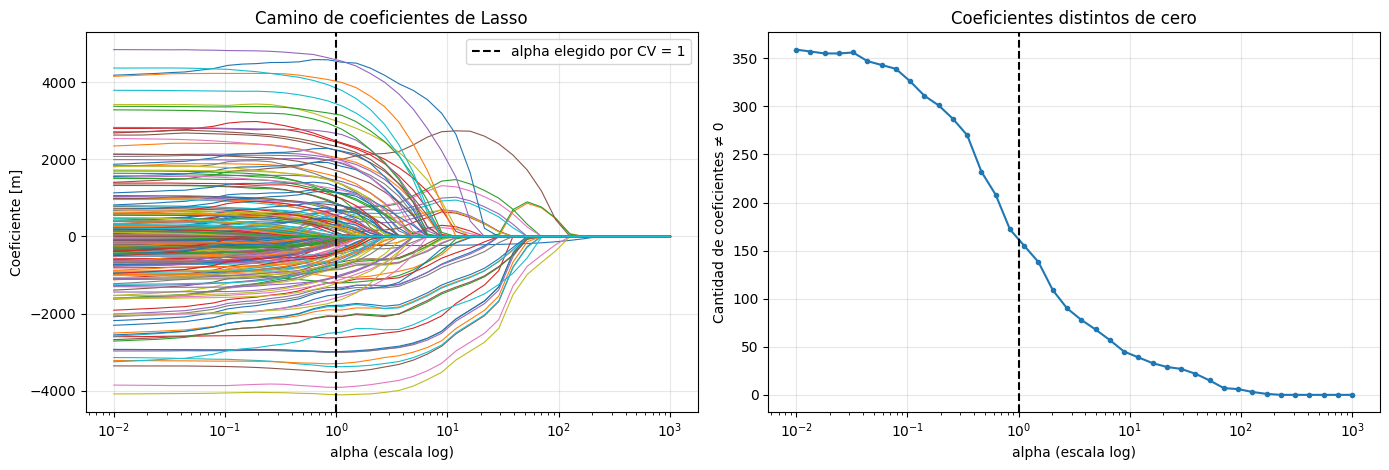

In [36]:
# 10.4 Camino de coeficientes de Lasso (alpha en escala logarítmica)
prep_path = crear_prep_reg(CAT_REG_ALL).fit(train[FEAT_REG_ALL])
Xr = prep_path.transform(train[FEAT_REG_ALL])
alphas = np.logspace(-2, 3, 40)
lasso_w = Lasso(max_iter=50000, warm_start=True)
camino = []
for a in alphas[::-1]:                    # de alpha grande a chico: warm start acelera la convergencia
    lasso_w.set_params(alpha=a).fit(Xr, yr_train)
    camino.append(lasso_w.coef_.copy())
camino = np.array(camino[::-1])
no_nulos = (camino != 0).sum(axis=1)
alpha_lasso = busquedas_reg['Lasso'].best_params_['modelo__alpha']

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(alphas, camino, lw=0.8)
ax[0].set_xscale('log')
ax[0].axvline(alpha_lasso, color='k', ls='--', label=f'alpha elegido por CV = {alpha_lasso}')
ax[0].set(title='Camino de coeficientes de Lasso', xlabel='alpha (escala log)', ylabel='Coeficiente [m]')
ax[0].legend()
ax[1].plot(alphas, no_nulos, 'o-', ms=3)
ax[1].set_xscale('log')
ax[1].axvline(alpha_lasso, color='k', ls='--')
ax[1].set(title='Coeficientes distintos de cero', xlabel='alpha (escala log)', ylabel='Cantidad de coeficientes ≠ 0')
plt.tight_layout()
plt.show()

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- Tarea de regresión sobre `Metros_Total` con `Año` + sucursal + tela + **interacción sucursal×tela**: **400 columnas** después del one-hot, muchas redundantes (las indicadoras de par contienen los efectos principales). Es un escenario típico para regularizar: `LinearRegression` lo resuelve con la solución de mínima norma, pero sus coeficientes no son identificables.
- Comparamos `LinearRegression`, `Ridge`, `Lasso` y `ElasticNet(l1_ratio=0.5)` con `alpha=1.0`, todos en un `Pipeline` con el preprocesamiento.
- `GridSearchCV` con 5 folds (KFold) para Ridge y Lasso con alpha en [0.01, 0.1, 1, 10, 100], optimizando RMSE.
- Para el camino de Lasso usamos 40 valores de alpha entre 10⁻² y 10³ (escala log), con *warm start* para acelerar la convergencia.

**Interpretación de los resultados:**
- **CV5 (RMSE / R²):** LinearRegression 1.213 / 0,727; **Ridge(1) 1.173 / 0,744; Lasso(1) 1.166 / 0,747**; ElasticNet(1) 2.212 / 0,094.
- ElasticNet con alpha = 1 queda cerca de la baseline. En la parametrización de scikit-learn, su penalización L2 equivale a un Ridge con alpha ≈ n·alpha·(1−l1_ratio) ≈ 1.000: demasiado fuerte para indicadoras 0/1. Hay que buscar su alpha y no fijarlo en 1.
- **GridSearchCV:** el mejor alpha es **1** tanto para Ridge como para Lasso. La curva tiene forma de U: con 0,01 el resultado es casi igual al de mínimos cuadrados (1.212); con 10 empeora (Ridge 1.275, Lasso 1.424) y con 100 mucho más (1.778 y 2.250).
- **Test:** Ridge y Lasso tienen RMSE **1.083,5 m** y R² **0,784**, contra 1.089,8 m y 0,781 de LinearRegression. La mejora es chica, pero el modelo es mucho más simple.
- **Coeficientes:** **Lasso(1) anula 238 de 400** y Lasso(100), 394 de 400. Ridge no anula ninguno, pero reduce la norma L2 de 21.400 a 19.386. Los coeficientes más grandes que conserva Lasso son interacciones puntuales (por ejemplo, sucursal 1 con TELA-015 o TELA-001, +4.500 m) y efectos de sucursal (9, 7 y 6, de −3.500 a −4.100 m).

**Pregunta de análisis:** ¿Qué diferencia hay entre L1 y L2? ¿Lasso anuló coeficientes? ¿Qué cambia al crecer alpha?
**L1 (Lasso)** penaliza la suma de |w|. Su geometría lleva coeficientes **exactamente a cero**, así que hace selección de variables. **L2 (Ridge)** penaliza la suma de w²: encoge todos los coeficientes hacia cero pero no los anula, y entre variables correlacionadas reparte el peso en lugar de elegir una.

**Sí, Lasso anuló coeficientes:** con el alpha elegido por CV dejó en cero 238 de 400 (casi todos interacciones de pares cuyo efecto ya explican la sucursal y la tela), sin perder desempeño. **Al crecer alpha**, el camino muestra que los coeficientes se encogen y van desapareciendo: de ~360 distintos de cero con alpha = 0,01, a ~160 con 1, ~45 con 10 y ninguno a partir de ~200, donde el modelo predice la media. Más alpha significa más sesgo y menos varianza. Pasado alpha = 1, el sesgo domina y el RMSE sube.

**Limitaciones o mejoras posibles:**
La grilla de 5 valores es gruesa; una búsqueda más fina alrededor de 1 (o `LassoCV`/`RidgeCV`) y buscar alpha y `l1_ratio` en ElasticNet podría mejorar algo. Las interacciones de pares no sirven para pares nuevos. La validación debería ser temporal si el objetivo es pronosticar años futuros.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 11 · k-NN y efecto del escalado

**Qué se espera:** Compará k-NN (k=5) sin y con escalado correcto; explorá k en [1, 3, 5, 7, 10, 15, 20, 30] con CV y reportá media ± std. Sumá k-NN a la tabla de modelos.

**Evidencia a entregar:** Comparación con/sin escalado y curva de k.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [37]:
# 11.1 k-NN (k=5) sin y con escalado (el escalador se ajusta dentro de cada fold, en el pipeline)
print('Desvío estándar de las features numéricas en train (sin escalar):')
print(train[NUM_CLF].std().round(3).to_string(), '\n')
knn_variantes = {
    'k-NN k=5 sin escalar': crear_pipeline_clf(KNeighborsClassifier(n_neighbors=5), usar_ids=False, escalar=False),
    'k-NN k=5 con StandardScaler': crear_pipeline_clf(KNeighborsClassifier(n_neighbors=5), usar_ids=False, escalar=True),
}
filas = []
for nombre, pipe in knn_variantes.items():
    s = cross_val_score(pipe, X_train, y_train, cv=cv10, scoring='f1_macro', n_jobs=-1)
    pipe.fit(X_train, y_train)
    m = metricas_clf(y_test, pipe.predict(X_test))
    registrar('11', 'Clasificación', nombre, m)
    filas.append({'Modelo': nombre, 'F1_macro_CV10': s.mean(), 'Std_CV10': s.std(), **{f'{k}_test': v for k, v in m.items()}})
display(pd.DataFrame(filas).set_index('Modelo').round(4))

Desvío estándar de las features numéricas en train (sin escalar):
Año                2.866
log_M1             1.361
log_ratio_M2_M1    0.429 



,F1_macro_CV10,Std_CV10,Accuracy_test,F1_macro_test,F1_weighted_test
Modelo,,,,,
k-NN k=5 sin escalar,0.8856,0.0175,0.8843,0.8869,0.8850
k-NN k=5 con StandardScaler,0.9275,0.0120,0.9254,0.9265,0.9254


,F1_train,F1_CV10,Std_CV10,Media ± std
k,,,,
1,1.0000,0.9157,0.0053,0.9157 ± 0.0053
3,0.9572,0.9253,0.0141,0.9253 ± 0.0141
5,0.9455,0.9275,0.0120,0.9275 ± 0.0120
7,0.9413,0.9316,0.0128,0.9316 ± 0.0128
10,0.9375,0.9265,0.0133,0.9265 ± 0.0133
15,0.9324,0.9222,0.0169,0.9222 ± 0.0169
20,0.9294,0.9242,0.0142,0.9242 ± 0.0142
30,0.9236,0.9191,0.0190,0.9191 ± 0.0190


k con mayor F1 CV (elegido): 7 | k más grande dentro de 1 desvío (referencia): 30


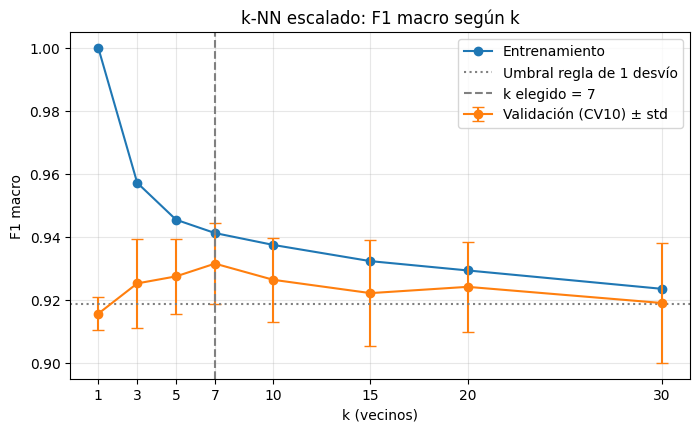

Tabla de modelos de clasificación (métricas de test históricas):


,Actividad,Accuracy,F1_macro,F1_weighted
Modelo,,,,
Baseline (más frecuente),01-02,0.2831,0.1103,0.1249
"LogReg (Año, Metros1, Metros2 crudas)",03,0.7336,0.7296,0.7356
"LogReg (Año, log_M1, log_ratio)",03,0.7686,0.7686,0.7670
Árbol gini (max_depth=4),05,0.9346,0.9357,0.9345
Árbol entropy (max_depth=4),05,0.9346,0.9358,0.9344
Random Forest (100 árboles),06,0.9422,0.9428,0.9421
"XGBoost (100, lr=0.1, depth=3)",06,0.9513,0.9519,0.9513
Random Forest + IDs one-hot (pipeline),09,0.9878,0.9876,0.9878
Random Forest sin IDs (pipeline),09,0.9422,0.9428,0.9421


In [38]:
# 11.2 Búsqueda de k por CV10 (sobre train)
ks = [1, 3, 5, 7, 10, 15, 20, 30]
filas = []
for k in ks:
    r = cross_validate(crear_pipeline_clf(KNeighborsClassifier(n_neighbors=k), usar_ids=False), X_train, y_train,
                       cv=cv10, scoring='f1_macro', return_train_score=True, n_jobs=-1)
    filas.append({'k': k, 'F1_train': r['train_score'].mean(), 'F1_CV10': r['test_score'].mean(), 'Std_CV10': r['test_score'].std()})
tabla_k = pd.DataFrame(filas).set_index('k')
tabla_k['Media ± std'] = [f'{a:.4f} ± {b:.4f}' for a, b in zip(tabla_k['F1_CV10'], tabla_k['Std_CV10'])]
display(tabla_k.round(4))

k_mejor = tabla_k['F1_CV10'].idxmax()
umbral = tabla_k.loc[k_mejor, 'F1_CV10'] - tabla_k.loc[k_mejor, 'Std_CV10']
k_1sd = max(k for k in ks if tabla_k.loc[k, 'F1_CV10'] >= umbral)   # referencia: el k más suave dentro de 1 desvío
print(f'k con mayor F1 CV (elegido): {k_mejor} | k más grande dentro de 1 desvío (referencia): {k_1sd}')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ks, tabla_k['F1_train'], 'o-', label='Entrenamiento')
ax.errorbar(ks, tabla_k['F1_CV10'], yerr=tabla_k['Std_CV10'], fmt='o-', capsize=4, label='Validación (CV10) ± std')
ax.axhline(umbral, color='gray', ls=':', label='Umbral regla de 1 desvío')
ax.axvline(k_mejor, color='gray', ls='--', label=f'k elegido = {k_mejor}')
ax.set_xticks(ks)
ax.set(title='k-NN escalado: F1 macro según k', xlabel='k (vecinos)', ylabel='F1 macro')
ax.legend()
plt.show()

knn_final = crear_pipeline_clf(KNeighborsClassifier(n_neighbors=k_mejor), usar_ids=False).fit(X_train, y_train)
registrar('11', 'Clasificación', f'k-NN k={k_mejor} escalado', metricas_clf(y_test, knn_final.predict(X_test)))
print('Tabla de modelos de clasificación (métricas de test históricas):')
display(tabla_historica('Clasificación').round(4))

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- k-NN dentro del mismo pipeline de la Act. 9 (sin IDs), en dos versiones: solo imputación y imputación + `StandardScaler`. El escalador se ajusta dentro de cada fold.
- Para k en [1, 3, 5, 7, 10, 15, 20, 30] usamos CV10 sobre train y reportamos train, media ± desvío de CV.
- Elegimos **el k con mayor F1 de CV**. Como referencia, calculamos también el k más grande dentro de un desvío del mejor (regla de 1 desvío).

**Interpretación de los resultados:**
- **k = 5 sin escalar:** F1 CV10 = 0,886 ± 0,018 (test 0,887). **Con escalado:** **0,928 ± 0,012** (test 0,927). Escalar suma 4,2 puntos.
- La causa está en los desvíos sin escalar: `Año` 2,87, `log_M1` 1,36 y `log_ratio` 0,43. Sin escalar, la distancia la domina `Año`, que es irrelevante para el formato, y la feature más importante (el cociente) es la que menos pesa.
- **Curva de k:** con k = 1, train = 1,000 y CV 0,916 (memoriza). El CV sube hasta **k = 7 (0,932 ± 0,013)** y luego baja hasta 0,919 en k = 30 (demasiado suave: mezcla vecinos de otras bandas). La regla de 1 desvío elegiría k = 30, pero preferimos k = 7 porque la caída a 0,919 es sistemática y no aporta ventaja de costo.
- k-NN k = 7 en test: F1 0,922. En la tabla de modelos queda por debajo de los árboles y los ensambles (0,936–0,952) y muy por encima de la LogReg (0,769).

**Pregunta de análisis:** ¿Por qué k-NN cambia con la escala y Random Forest generalmente no? ¿Cómo justificás k?
**k-NN** clasifica según distancias, y en la distancia euclídea cada feature contribuye en proporción a su escala: la de mayor rango domina sin importar su relevancia. **Random Forest** usa cortes del tipo "x ≤ umbral" en una feature por vez. Una transformación monótona como el escalado cambia el valor del umbral pero no el orden de los datos, así que las particiones y las predicciones son las mismas.

**Justificación de k:** lo elegimos por CV sobre train, sin mirar test. Un k chico tiene poco sesgo y mucha varianza (k = 1 memoriza: train 1,0); uno grande suaviza demasiado y pierde las bandas estrechas del cociente. El máximo está en k = 7 (0,932). Entre 5 y 10 las diferencias quedan dentro de un desvío, así que el resultado no es sensible a la elección exacta en ese rango.

**Limitaciones o mejoras posibles:**
El costo de predicción de k-NN crece con el tamaño de train. Podrían probarse `weights='distance'`, la distancia Manhattan (que en la U6 mejoró el desempeño) y eliminar `Año`, que solo agrega ruido a la distancia.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 12 · Clustering: k-means y jerárquico

**Qué se espera:** Sin usar el target, escalá features numéricas y evaluá k-means para k=2..10 mediante inercia y silueta. Interpretá centroides/perfiles; aplicá clustering jerárquico con Ward y dendrograma truncado; visualizá segmentos en 2D o PCA.

**Evidencia a entregar:** Codo, silueta, perfiles, dendrograma y visualización interpretada.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


k,2,3,4,5,6,7,8,9,10
Inercia,5170.701,3946.534,3178.845,2619.862,2115.217,1726.651,1503.249,1323.832,1199.838
Silueta,0.368,0.348,0.373,0.362,0.383,0.380,0.377,0.397,0.378


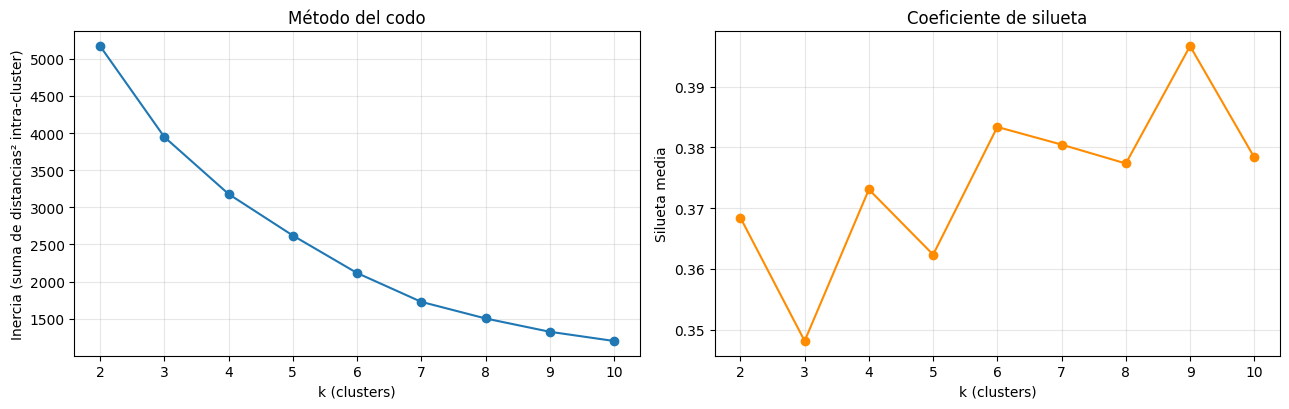

In [39]:
# 12.1 k-means sin target: escala del período 1, forma del reporte y volumen anual (en log, escaladas)
FEAT_CLU = ['log_M1', 'log_ratio_M2_M1', 'log_Total']
clu = train.assign(log_Total=np.log1p(train[TARGET_REG]))
Xc = StandardScaler().fit_transform(clu[FEAT_CLU])

ks_clu = list(range(2, 11))
inercias, siluetas = [], []
for k in ks_clu:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(Xc, km.labels_))
display(pd.DataFrame({'k': ks_clu, 'Inercia': inercias, 'Silueta': siluetas}).set_index('k').round(3).T)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(ks_clu, inercias, 'o-')
ax[0].set(title='Método del codo', xlabel='k (clusters)', ylabel='Inercia (suma de distancias² intra-cluster)')
ax[1].plot(ks_clu, siluetas, 'o-', color='darkorange')
ax[1].set(title='Coeficiente de silueta', xlabel='k (clusters)', ylabel='Silueta media')
plt.tight_layout()
plt.show()

In [40]:
# 12.2 Perfiles de los segmentos (unidades originales) — el target solo se usa después, para comparar
K_CLU = 4
km = KMeans(n_clusters=K_CLU, n_init=10, random_state=RANDOM_STATE).fit(Xc)
clu['cluster_km'] = km.labels_
perfil = clu.groupby('cluster_km').agg(
    registros=('Metros1', 'size'), mediana_Metros1=('Metros1', 'median'), mediana_Metros2=('Metros2', 'median'),
    mediana_ratio_M2_M1=('log_ratio_M2_M1', lambda s: np.exp(s.median())), mediana_Metros_Total=(TARGET_REG, 'median'))
display(perfil.round(2))
print('Centroides en desvíos estándar:')
display(pd.DataFrame(km.cluster_centers_, columns=FEAT_CLU).round(2))
print('Comparación a posteriori con Format_Reporte (proporción de cada cluster):')
display(pd.crosstab(clu['cluster_km'], clu[TARGET_CLF], normalize='index').round(2))
print(f"Adjusted Rand Index (k-means vs. Format_Reporte): {adjusted_rand_score(clu[TARGET_CLF], clu['cluster_km']):.3f}")

,registros,mediana_Metros1,mediana_Metros2,mediana_ratio_M2_M1,mediana_Metros_Total
cluster_km,,,,,
0,153,373.65,1228.86,3.14,1628.86
1,1126,238.40,269.75,1.06,2106.62
2,185,39.96,41.98,1.00,229.48
3,1164,1486.52,1341.44,0.96,3365.30


Centroides en desvíos estándar:


,log_M1,log_ratio_M2_M1,log_Total
0,-0.15,2.61,-0.30
1,-0.55,0.20,-0.05
2,-1.94,-0.35,-2.51
3,0.86,-0.48,0.49


Comparación a posteriori con Format_Reporte (proporción de cada cluster):


Format_Reporte,B,C,M,S
cluster_km,,,,
0,0.00,0.54,0.00,0.46
1,0.44,0.05,0.41,0.11
2,0.21,0.23,0.38,0.17
3,0.05,0.44,0.07,0.44


Adjusted Rand Index (k-means vs. Format_Reporte): 0.230


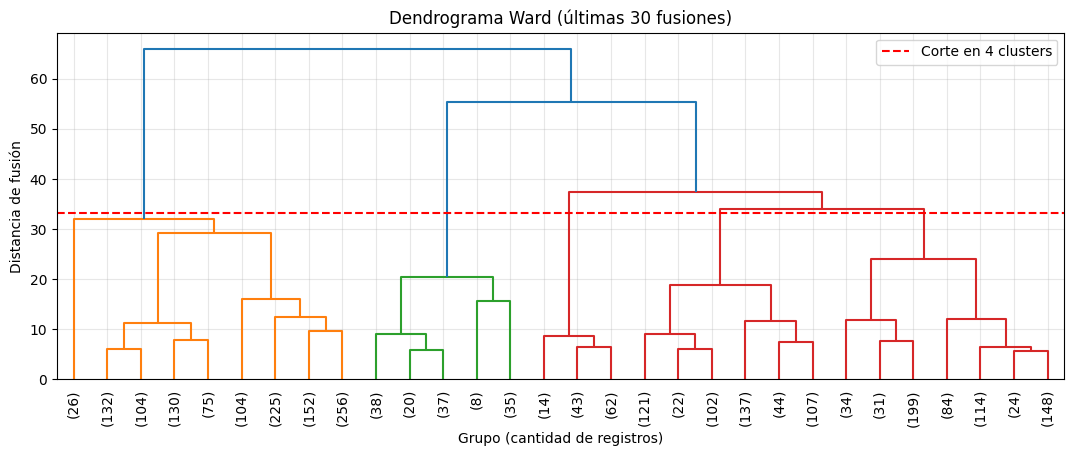

Silueta Ward (4 clusters): 0.371 | k-means: 0.373
Coincidencia Ward vs. k-means (ARI): 0.569


Ward,1,2,3,4
k-means,,,,
0,0,0,119,34
1,174,0,0,952
2,2,138,0,45
3,1028,0,0,136


In [41]:
# 12.3 Clustering jerárquico (Ward) y dendrograma truncado
Z = linkage(Xc, method='ward')
fig, ax = plt.subplots(figsize=(13, 4.5))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True, leaf_rotation=90, ax=ax)
ax.axhline(Z[-K_CLU, 2] * 0.98, color='red', ls='--', label=f'Corte en {K_CLU} clusters')
ax.set(title='Dendrograma Ward (últimas 30 fusiones)', xlabel='Grupo (cantidad de registros)', ylabel='Distancia de fusión')
ax.legend()
plt.show()
clu['cluster_ward'] = fcluster(Z, t=K_CLU, criterion='maxclust')
print(f"Silueta Ward ({K_CLU} clusters): {silhouette_score(Xc, clu['cluster_ward']):.3f} | "
      f"k-means: {silhouette_score(Xc, clu['cluster_km']):.3f}")
print(f"Coincidencia Ward vs. k-means (ARI): {adjusted_rand_score(clu['cluster_km'], clu['cluster_ward']):.3f}")
display(pd.crosstab(clu['cluster_km'], clu['cluster_ward'], rownames=['k-means'], colnames=['Ward']))

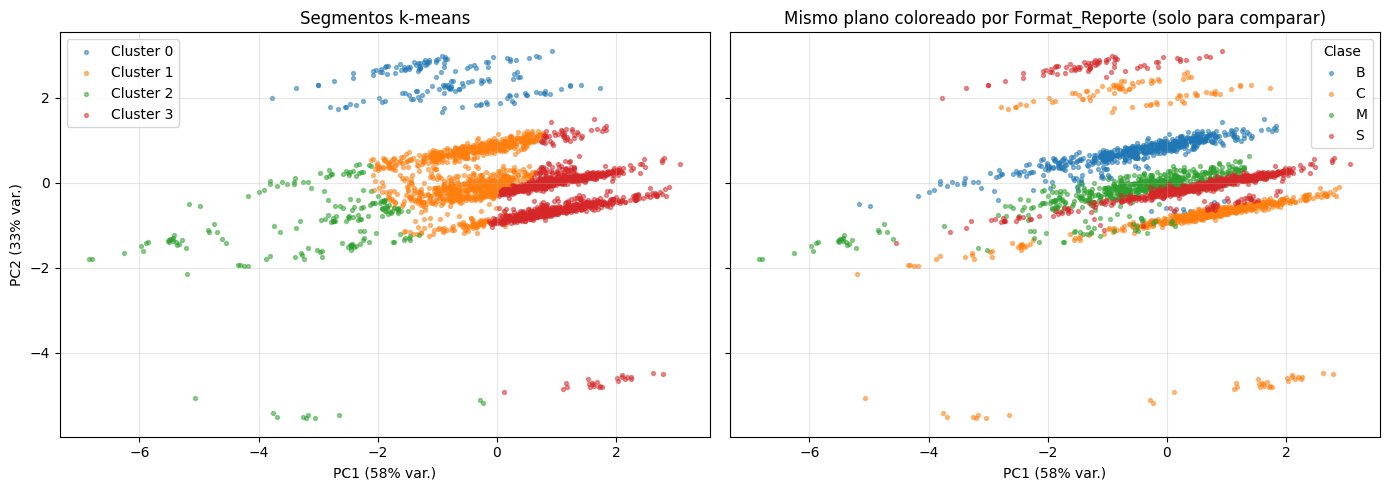

,log_M1,log_ratio_M2_M1,log_Total
PC1,0.71,-0.20,0.68
PC2,-0.00,0.96,0.29


In [42]:
# 12.4 Visualización en 2D con PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(Xc)
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for c in range(K_CLU):
    ax[0].scatter(P[clu['cluster_km'] == c, 0], P[clu['cluster_km'] == c, 1], s=8, alpha=0.5, label=f'Cluster {c}')
ax[0].set(title='Segmentos k-means', xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.0%} var.)',
          ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.0%} var.)')
ax[0].legend()
for c in CLASES:
    ax[1].scatter(P[clu[TARGET_CLF] == c, 0], P[clu[TARGET_CLF] == c, 1], s=8, alpha=0.5, label=c)
ax[1].set(title='Mismo plano coloreado por Format_Reporte (solo para comparar)',
          xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.0%} var.)')
ax[1].legend(title='Clase')
plt.tight_layout()
plt.show()
display(pd.DataFrame(pca.components_, columns=FEAT_CLU, index=['PC1', 'PC2']).round(2))

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- Features sin target: `log_M1` (escala del primer período), `log_ratio_M2_M1` (forma) y `log_Total` (volumen anual), las tres en log por la asimetría y escaladas con `StandardScaler`. Usamos **solo train**, para no tocar test.
- k-means con k = 2..10 (`n_init=10`), evaluado por inercia y silueta. Elegimos **k = 4**: el codo de la inercia está alrededor de 4 (5.171 → 3.947 → 3.179, después las bajas son menores) y la silueta tiene ahí un máximo local (0,373). La silueta máxima está en k = 9 (0,397), pero 9 segmentos no son accionables y la mejora es chica.
- El target se usa **solo después**, para comparar (tabla cruzada y ARI).
- Comparamos con clustering jerárquico Ward (dendrograma truncado en las últimas 30 fusiones) y visualizamos con PCA en 2D.

**Interpretación de los resultados:**
- **Cluster 0 (153 registros):** cociente ≈ 3,1 (el segundo período triplica al primero) y total de 1.629 m. Son reportes de 2 períodos (54% C, 46% S) con un reparto muy desparejo.
- **Cluster 1 (1.126):** primer período chico (~238 m), cociente ≈ 1,06 y total de 2.107 m. Son mayormente formatos desagregados (44% B, 41% M).
- **Cluster 2 (185):** **muy bajo volumen** (total de 229 m/año) con formatos mezclados.
- **Cluster 3 (1.164):** primer período grande (~1.487 m), cociente ≈ 0,96 y el mayor total (3.365 m). Son mayormente C y S (44% cada uno).
- **ARI k-means contra formato = 0,23:** hay algo de relación, pero lejos de una correspondencia. Ward da una silueta parecida (0,371) y coincide moderadamente con k-means (ARI 0,57): los grupos grandes se reproducen y las diferencias están en los bordes.
- En el PCA, **PC1 = volumen/escala** (0,71·log_M1 + 0,68·log_Total) y **PC2 = forma** (0,96·log_ratio). Los clusters cortan sobre todo a lo largo de PC1, mientras que los formatos se separan en bandas a lo largo de PC2.

**Pregunta de análisis:** ¿Qué grupos de ventas aparecen? ¿Los clusters tienen utilidad comercial? ¿Por qué no equivalen a las clases del target?
Aparecen cuatro grupos: **alto volumen con reporte en 2 períodos**, **volumen medio con reporte desagregado**, **muy bajo volumen** y **reparto atípico entre períodos**. Tienen **utilidad comercial parcial**. El cluster de bajo volumen (229 m/año) señala combinaciones sucursal-tela de baja rotación, candidatas a revisar surtido o stock. El cluster de alto volumen identifica las combinaciones prioritarias para abastecimiento, y el de cociente atípico sirve como alerta de calidad de datos o de estacionalidad marcada. El límite es que `log_M1` depende del largo del período, así que parte de la segmentación refleja **cómo se reporta** y no solo cuánto se vende. Para una segmentación puramente comercial convendría usar el total anual y un perfil estacional normalizado.

**No equivalen a las clases** porque k-means no conoce el target: busca grupos compactos en la escala de las features, y la mayor varianza de los datos es el volumen (PC1), no el formato. Los formatos se diferencian por bandas angostas de cociente (C ≈ 0,77, S ≈ M ≈ 1, B ≈ 1,5) que se superponen en escala con la variación de volumen entre sucursales. Por ejemplo, M y S tienen el mismo cociente y solo difieren en escala, que también varía mucho dentro de cada formato.

**Limitaciones o mejoras posibles:**
k-means supone grupos esféricos de tamaño parecido, y las bandas del cociente son alargadas: un método basado en densidad (DBSCAN) o un modelo de mezclas podría capturarlas mejor. Una silueta de ~0,37 indica una estructura moderada. Los perfiles deberían validarse con el área comercial.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 13 · Comparativa y modelo candidato · Parcial 2

**Qué se espera:** Construí la tabla completa de modelos con media CV, std CV y métrica test histórica. Elegí un candidato y justificá en al menos 200 palabras desempeño, estabilidad, interpretación, costo y mantenimiento. Verificá pipeline y cinco predicciones.

**Evidencia a entregar:** Notebooks 01–13; tabla; justificación; commit `entrega-parcial-2`; tag `parcial-2`.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [43]:
# 13.1 Tabla comparativa: todos los modelos de clasificación como pipelines sobre columnas crudas
xgb_base = ClasificadorEtiquetado(XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                                                random_state=RANDOM_STATE, n_jobs=-1))
candidatos = {   # nombre: (modelo, usar_ids)
    'Baseline (más frecuente)': (DummyClassifier(strategy='most_frequent'), False),
    'LogReg (Año, log_M1, log_ratio)': (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), False),
    'Árbol gini (max_depth=4)': (DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=RANDOM_STATE), False),
    'Árbol entropy (max_depth=4)': (DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=RANDOM_STATE), False),
    'Random Forest (100 árboles)': (clone(rf_base), False),
    'XGBoost (100, lr=0.1, depth=3)': (xgb_base, False),
    f'k-NN k={k_mejor} escalado': (KNeighborsClassifier(n_neighbors=k_mejor), False),
    'Random Forest + IDs one-hot (pipeline)': (clone(rf_base), True),
}
test_hist = tabla_historica('Clasificación')['F1_macro']
filas = []
for nombre, (modelo, usar_ids) in candidatos.items():
    pipe = crear_pipeline_clf(clone(modelo), usar_ids=usar_ids)
    r = cross_validate(pipe, X_train, y_train, cv=cv10, scoring='f1_macro', n_jobs=-1)
    g = cross_val_score(pipe, X_train, y_train, cv=cv_grupos, groups=grupos_train, scoring='f1_macro', n_jobs=-1)
    filas.append({'Modelo': nombre, 'F1_CV10_media': r['test_score'].mean(), 'F1_CV10_std': r['test_score'].std(),
                  'F1_CV_grupos': g.mean(), 'F1_test_histórico': test_hist.get(nombre, np.nan),
                  'Tiempo_ajuste_s': r['fit_time'].mean()})
tabla_modelos = pd.DataFrame(filas).set_index('Modelo').sort_values('F1_CV10_media', ascending=False)
tabla_modelos.to_csv(DIR_OUT / 'tabla_modelos_clasificacion.csv')
display(tabla_modelos.round(4))

,F1_CV10_media,F1_CV10_std,F1_CV_grupos,F1_test_histórico,Tiempo_ajuste_s
Modelo,,,,,
Random Forest + IDs one-hot (pipeline),0.9820,0.0084,0.9169,0.9876,0.6470
"XGBoost (100, lr=0.1, depth=3)",0.9471,0.0070,0.9366,0.9519,0.2437
Random Forest (100 árboles),0.9425,0.0082,0.9340,0.9428,0.4607
Árbol gini (max_depth=4),0.9389,0.0068,0.9310,0.9357,0.0338
Árbol entropy (max_depth=4),0.9382,0.0063,0.9293,0.9358,0.0358
k-NN k=7 escalado,0.9316,0.0128,0.9256,0.9219,0.0284
"LogReg (Año, log_M1, log_ratio)",0.7600,0.0207,0.7577,0.7686,0.0388
Baseline (más frecuente),0.1101,0.0004,0.1101,0.1103,0.0218


In [44]:
# 13.2 Modelo candidato: XGBoost sin identificadores (ver justificación) — verificación del pipeline
CANDIDATO = 'XGBoost (100, lr=0.1, depth=3)'
pipe_candidato = crear_pipeline_clf(clone(candidatos[CANDIDATO][0]), usar_ids=False).fit(X_train, y_train)
display(pipe_candidato)

cinco = X_test.head(5)
verif = cinco.copy()
verif['Real'] = y_test.head(5).values
verif['Predicho'] = pipe_candidato.predict(cinco)
proba = pd.DataFrame(pipe_candidato.predict_proba(cinco), columns=[f'P({c})' for c in pipe_candidato.classes_], index=cinco.index)
display(pd.concat([verif, proba.round(3)], axis=1))
assert list(pipe_candidato.classes_) == CLASES

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['B','C','M','S']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Sucursal_ID','Año','Tela_ID','Metros1','Metros2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function agr...0019C6299B060>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


,Sucursal_ID,Año,Tela_ID,Metros1,Metros2,Real,Predicho,P(B),P(C),P(M),P(S)
fila,,,,,,,,,,,
5,1,2016,TELA-006,342.56,338.92,M,M,0.005,0.004,0.782,0.208
13,1,2016,TELA-014,2549.20,1933.51,C,C,0.002,0.996,0.000,0.002
14,1,2016,TELA-015,1609.92,2320.64,B,B,0.992,0.001,0.001,0.007
18,1,2016,TELA-019,106.61,113.41,M,M,0.003,0.003,0.977,0.018
21,1,2016,TELA-022,3379.91,3369.55,S,S,0.000,0.001,0.001,0.998


### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- Rearmamos **todos los modelos de clasificación como pipelines sobre columnas crudas** y los evaluamos con la misma CV10. Sumamos la CV agrupada por par sucursal-tela y el tiempo de ajuste, y agregamos el F1 de test histórico de cada actividad (solo como referencia; no guía la elección). La tabla se guarda en `outputs/tabla_modelos_clasificacion.csv`.
- **Candidato: XGBoost sin identificadores** (`log_M1`, `log_ratio_M2_M1`, `Año`), dentro del pipeline completo.

**Justificación de la elección:**

- **Desempeño.** Es el mejor modelo de los que no usan identificadores, con F1 macro CV10 = 0,947. Supera al árbol en los 10 folds y al Random Forest en 7 de 10 (Act. 7). La diferencia con el RF es chica (0,5 puntos), pero consistente.
- **Estabilidad.** Su desvío entre folds es de 0,007, similar al de los otros modelos de árboles y muy por debajo de 0,02. Además, es el que **menos cae con pares sucursal-tela no vistos** (0,937 en la CV agrupada, contra 0,934 del RF y 0,917 del RF con IDs). Eso es lo que más importa si el modelo se usa con sucursales o telas nuevas, o con combinaciones que no estaban en el histórico.
- **Interpretación.** Es menos legible que un árbol de profundidad 4, pero trabaja sobre solo tres features con sentido de negocio (escala y forma del reporte). Sus importancias coinciden con las reglas del árbol, y se le puede aplicar SHAP para explicar casos individuales. Si la prioridad fuera explicar cada decisión con reglas, el árbol de profundidad 4 sería la alternativa: pierde unos 0,8 puntos.
- **Costo.** Se ajusta en ~0,2 s, predice 657 filas en menos de 10 ms y el archivo serializado pesa ~350 KB. Es más liviano que el Random Forest en predicción y en disco.
- **Mantenimiento.** Solo necesita las 5 columnas crudas que siempre están completas. No depende de un vocabulario de sucursales o telas que haya que actualizar cuando aparecen nuevas. Las transformaciones son fila a fila y viven versionadas en `src/`.

La verificación del pipeline sobre cinco registros devuelve las clases originales y probabilidades coherentes: los cinco aciertan, y el único caso con probabilidad < 0,8 es un M con cociente ≈ 1, la zona de confusión con S.

**Interpretación de los resultados:**
- El ranking por CV10 lo encabeza **Random Forest + IDs (0,982)**, seguido por XGBoost (0,947), Random Forest (0,943), los árboles (0,939 y 0,938), k-NN k = 7 (0,932), la LogReg (0,760) y la baseline (0,110).
- Con la CV por grupos, el orden cambia: XGBoost (0,937) > RF (0,934) > árboles (0,931 y 0,929) > k-NN (0,926) > **RF + IDs (0,917)**.
- Las métricas de test históricas reproducen el ranking de la CV aleatoria, incluido el valor inflado de RF + IDs (0,988).

**Pregunta de análisis:** ¿Por qué elegís este modelo y no el que tiene la mejor métrica aislada?
Porque **la mejor métrica aislada (RF + IDs, 0,982 en CV y 0,988 en test) proviene de memorización y no de aprendizaje**. Cada par sucursal-tela tiene siempre el mismo formato, y el 100% de los pares de test está en train, así que con los IDs el modelo "recuerda" el formato del par. Cuando evaluamos sobre pares no vistos, ese modelo cae al último lugar entre los de árboles (0,917). Además, para un par ya conocido no hace falta un modelo: alcanza con una tabla de búsqueda. El valor de un modelo predictivo está en los datos nuevos, y ahí el XGBoost sin IDs es el mejor. También pesaron la estabilidad, el costo y el mantenimiento descritos arriba.

**Limitaciones o mejoras posibles:**
Ya consultamos el test varias veces como métrica histórica. Por eso la evaluación que vale es la única que se hace en la Act. 15 con la configuración final. Las diferencias entre XGBoost y RF son chicas y podrían invertirse con otra semilla.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 14 · Laboratorio del modelo final

**Qué se espera:** Partiendo del pipeline candidato, ejecutá GridSearchCV con al menos 3 hiperparámetros y 3 valores por parámetro. Reportá configuración, métrica y evaluación final prevista; prepará borrador de README con reproducción y resultados.

**Evidencia a entregar:** GridSearchCV, análisis de errores y README borrador.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [45]:
# 14.1 GridSearchCV sobre el pipeline candidato: 3 hiperparámetros × 3 valores = 27 configuraciones × 10 folds
grilla = {
    'modelo__estimador__n_estimators': [100, 200, 400],
    'modelo__estimador__max_depth': [2, 3, 5],
    'modelo__estimador__learning_rate': [0.03, 0.1, 0.3],
}
busqueda = GridSearchCV(crear_pipeline_clf(clone(xgb_base), usar_ids=False), grilla, scoring='f1_macro',
                        cv=cv10, n_jobs=-1, refit=True, return_train_score=True)
t0 = time.perf_counter()
busqueda.fit(X_train, y_train)
print(f'Búsqueda completada en {time.perf_counter() - t0:.1f} s')
print('Mejor configuración (CV10):', busqueda.best_params_)
print(f'Mejor F1 macro CV10: {busqueda.best_score_:.4f} ± {busqueda.cv_results_["std_test_score"][busqueda.best_index_]:.4f}')

res = pd.DataFrame(busqueda.cv_results_)
cols_param = [c for c in res.columns if c.startswith('param_')]
top = (res[cols_param + ['mean_train_score', 'mean_test_score', 'std_test_score', 'mean_fit_time', 'rank_test_score']]
       .sort_values('rank_test_score').head(10))
top.columns = [c.replace('param_modelo__estimador__', '') for c in top.columns]
display(top.round(4))

Búsqueda completada en 14.1 s
Mejor configuración (CV10): {'modelo__estimador__learning_rate': 0.3, 'modelo__estimador__max_depth': 2, 'modelo__estimador__n_estimators': 100}
Mejor F1 macro CV10: 0.9508 ± 0.0088


,learning_rate,max_depth,n_estimators,mean_train_score,mean_test_score,std_test_score,mean_fit_time,rank_test_score
18,0.30,2,100,0.9698,0.9508,0.0088,0.2493,1
7,0.03,5,200,0.9717,0.9501,0.0083,0.7572,2
5,0.03,3,400,0.9657,0.9497,0.0082,1.0319,3
15,0.10,5,100,0.9833,0.9496,0.0083,0.3698,4
13,0.10,3,200,0.9782,0.9493,0.0076,0.5630,5
11,0.10,2,400,0.9747,0.9493,0.0090,0.8288,6
8,0.03,5,400,0.9870,0.9485,0.0099,1.3781,7
21,0.30,3,100,0.9875,0.9477,0.0073,0.2793,8
19,0.30,2,200,0.9811,0.9476,0.0090,0.4309,9
10,0.10,2,200,0.9614,0.9475,0.0087,0.4263,10


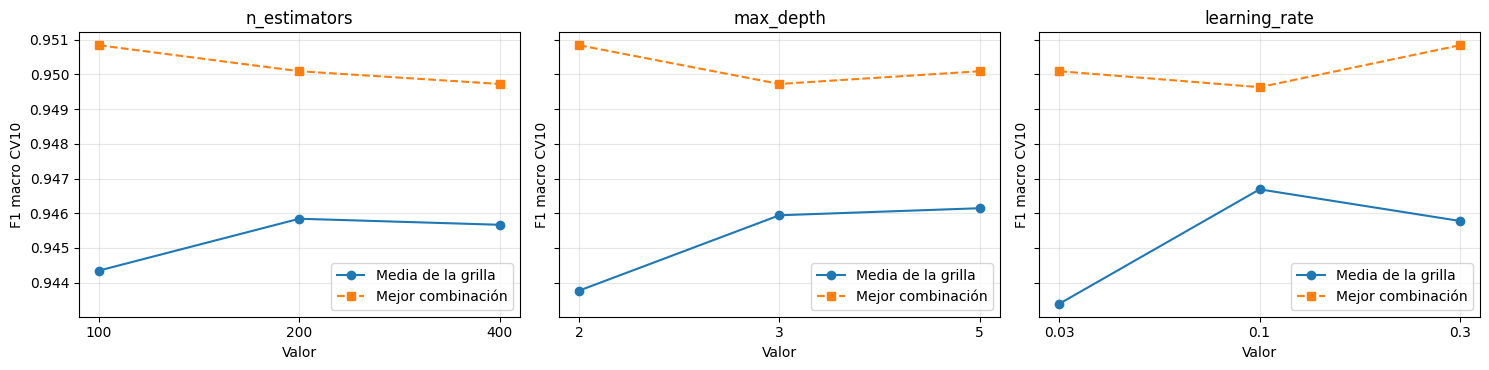

In [46]:
# 14.2 Sensibilidad a cada hiperparámetro (promedio del F1 CV sobre el resto de la grilla)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, p in zip(ax, grilla):
    g = res.groupby(f'param_{p}')['mean_test_score'].agg(['mean', 'max'])
    a.plot(g.index.astype(str), g['mean'], 'o-', label='Media de la grilla')
    a.plot(g.index.astype(str), g['max'], 's--', label='Mejor combinación')
    a.set(title=p.replace('modelo__estimador__', ''), xlabel='Valor', ylabel='F1 macro CV10')
    a.legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           B      0.986     0.968     0.977       586
           C      0.959     0.977     0.968       688
           M      0.897     0.953     0.924       612
           S      0.962     0.910     0.935       742

    accuracy                          0.950      2628
   macro avg      0.951     0.952     0.951      2628
weighted avg      0.951     0.950     0.950      2628



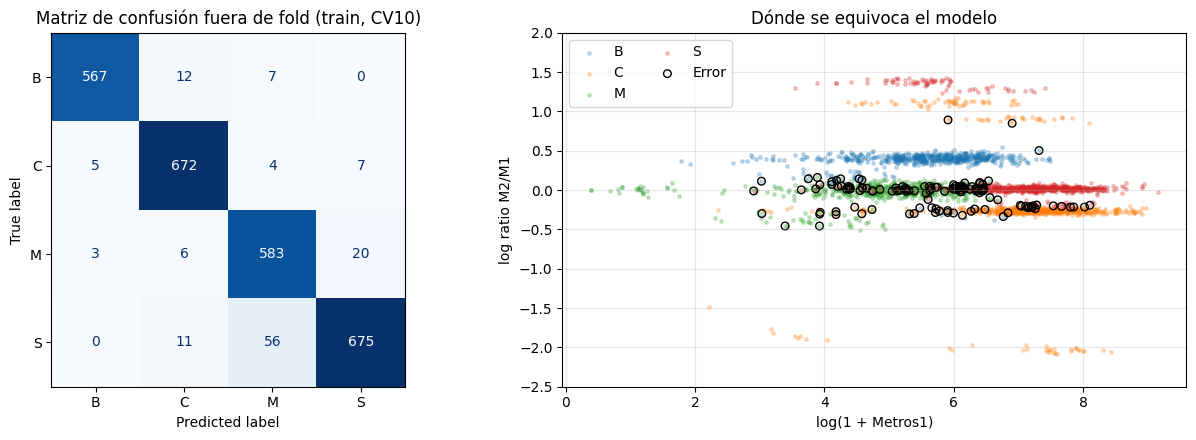

Pares (real -> predicho) más frecuentes entre los errores:


,,errores
Format_Reporte,pred,
S,M,56
M,S,20
B,C,12
S,C,11
B,M,7
C,S,7


Perfil de aciertos vs. errores (medianas):


,Metros1,Metros2,log_ratio_M2_M1
error,,,
False,563.42,686.52,0.016
True,366.30,314.11,0.003


In [47]:
# 14.3 Análisis de errores con predicciones fuera de fold sobre train (no se usa test)
pred_oof = cross_val_predict(busqueda.best_estimator_, X_train, y_train, cv=cv10, n_jobs=-1)
print(classification_report(y_train, pred_oof, digits=3))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ConfusionMatrixDisplay.from_predictions(y_train, pred_oof, ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Matriz de confusión fuera de fold (train, CV10)')
ax[0].grid(False)
errores = train.assign(pred=pred_oof, error=pred_oof != y_train)
for c in CLASES:
    sub = errores[errores[TARGET_CLF] == c]
    ax[1].scatter(sub['log_M1'], sub['log_ratio_M2_M1'], s=6, alpha=0.25, label=c)
mal = errores[errores['error']]
ax[1].scatter(mal['log_M1'], mal['log_ratio_M2_M1'], s=30, facecolors='none', edgecolors='k', label='Error')
ax[1].set(title='Dónde se equivoca el modelo', xlabel='log(1 + Metros1)', ylabel='log ratio M2/M1', ylim=(-2.5, 2))
ax[1].legend(ncol=2)
plt.tight_layout()
plt.show()
print('Pares (real -> predicho) más frecuentes entre los errores:')
display(mal.groupby([TARGET_CLF, 'pred']).size().sort_values(ascending=False).rename('errores').head(6).to_frame())
print('Perfil de aciertos vs. errores (medianas):')
display(errores.groupby('error')[['Metros1', 'Metros2', 'log_ratio_M2_M1']].median().round(3))

In [48]:
# 14.4 Evaluación final prevista (todavía sin tocar test)
MEJOR_CONFIG = {k.replace('modelo__estimador__', ''): v for k, v in busqueda.best_params_.items()}
std_mejor = busqueda.cv_results_['std_test_score'][busqueda.best_index_]
f1_grupos_final = cross_val_score(busqueda.best_estimator_, X_train, y_train, cv=cv_grupos, groups=grupos_train,
                                  scoring='f1_macro', n_jobs=-1).mean()
print('Configuración que se evaluará una única vez en test (Act. 15):', MEJOR_CONFIG)
print(f'Rango esperable de F1 macro en test según CV10: {busqueda.best_score_ - 2 * std_mejor:.3f} a {busqueda.best_score_ + 2 * std_mejor:.3f}')
print(f'F1 macro con validación agrupada por par sucursal-tela (pares no vistos): {f1_grupos_final:.4f}')

Configuración que se evaluará una única vez en test (Act. 15): {'learning_rate': 0.3, 'max_depth': 2, 'n_estimators': 100}
Rango esperable de F1 macro en test según CV10: 0.933 a 0.968
F1 macro con validación agrupada por par sucursal-tela (pares no vistos): 0.9377


### Borrador de README (versión preliminar de la Act. 14)

> **Ortelana Textil — clasificación de `Format_Reporte`**
>
> **Objetivo.** Predecir con qué formato de períodos (B, C, M, S) se cargó un registro sucursal-año-tela, a partir de `Metros1`, `Metros2` y `Año`. Problema secundario: regresión de `Metros_Total` (metros vendidos en el año).
>
> **Datos.** `ventas_historicas_ortelana_argentina.csv`: 3.285 registros, 12 sucursales, 30 telas, 2016–2025. Excluimos `Metros3..12` (proxy del formato) y los IDs (memorización por par).
>
> **Reproducción.** (1) `pip install -r requirements.txt`; (2) ejecutar el notebook en orden (la partición se guarda en `data/split_indices.csv`); (3) `python src/predecir.py --entrada <csv> --salida <csv>`.
>
> **Resultados preliminares (CV10 en train).** Baseline 0,110 · LogReg 0,760 · Árbol 0,939 · RF 0,943 · **XGBoost ajustado 0,951** (lr = 0,3, depth = 2, 100 árboles). Validación agrupada por par: 0,938.
>
> **Pendiente.** Evaluación única en test, serialización y script de predicción (Act. 15–16). La versión final del README la genera la celda 15.3.

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- `GridSearchCV` sobre el **pipeline candidato completo**, con 3 hiperparámetros × 3 valores = 27 configuraciones: `n_estimators` ∈ {100, 200, 400} (cantidad de árboles), `max_depth` ∈ {2, 3, 5} (complejidad de cada árbol) y `learning_rate` ∈ {0.03, 0.1, 0.3} (tamaño del paso).
- `scoring='f1_macro'`, CV10 (los mismos folds de antes), `refit=True` y `return_train_score=True` para vigilar la brecha.
- **Análisis de errores** con `cross_val_predict` sobre train (predicciones fuera de fold). El test no se toca.
- Estimamos la evaluación final esperada (media ± 2 desvíos de CV) y el desempeño sobre pares no vistos.

**Interpretación de los resultados:**
- **Mejor configuración:** `learning_rate=0.3`, `max_depth=2`, `n_estimators=100`, con F1 CV10 = **0,9508 ± 0,0088**. Frente a la configuración de la consigna (0,9471), la mejora es de 0,4 puntos, dentro de un desvío.
- Las 10 mejores configuraciones están entre 0,9475 y 0,9508: es una **meseta**, y el modelo es poco sensible a los hiperparámetros en esta grilla. Las combinaciones más profundas o con más árboles suben el F1 de train (hasta 0,987) sin mejorar el CV, así que agregan sobreajuste. Ganó la más simple (árboles de profundidad 2) y una de las más rápidas (0,25 s).
- **Errores (train, fuera de fold):** accuracy 0,950 y F1 macro 0,951. **El error dominante es S → M (56 casos) y M → S (20)**: registros con cociente ≈ 1 en los que solo la escala separa las clases. Los errores tienen metros más bajos (mediana de Metros1 366 m contra 563 m en los aciertos): un S de baja venta "parece" un reporte mensual. Le sigue B → C (12). M tiene precisión 0,897 y S recall 0,910.
- **Evaluación final prevista:** F1 macro en test esperable entre **0,933 y 0,968**. Sobre pares no vistos, la CV agrupada da 0,938.

**Pregunta de análisis:** ¿Qué errores de negocio son más costosos? ¿Qué métrica deberías optimizar?
Los errores más costosos son los que **cambian la cantidad de períodos**, porque llevan a interpretar mal la magnitud de los metros. **S ↔ M** (2 contra 12 períodos) es el más grave y además el más frecuente: un valor semestral leído como mensual multiplica por 6 la venta implícita. **B ↔ M** o **B ↔ C** también cambian la escala. **C ↔ S** es el menos costoso: ambos tienen 2 períodos y el mismo total anual.

**Métrica a optimizar:** **F1 macro**. Las clases están balanceadas y todas importan por igual, así que el F1 macro evita que una clase quede relegada y equilibra precisión y recall. Como complemento, monitorearíamos el **recall de S y de M**, que concentran los errores. Si el negocio cuantificara el costo de cada confusión, lo ideal sería optimizar una métrica con matriz de costos o ajustar umbrales por clase, por ejemplo derivar a revisión manual los casos con P(S) y P(M) parecidas.

**Limitaciones o mejoras posibles:**
La grilla es chica: se podría usar `early_stopping` en XGBoost o explorar `min_child_weight` y `subsample`. La mejora sobre la configuración base está dentro del ruido. Una búsqueda optimizada sobre una sola partición tiene un leve sesgo optimista, que en la práctica es pequeño por la meseta.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 15 · Selección final y ajuste fino

**Qué se espera:** Revisá reproducibilidad de notebooks, reentrená con todos los datos de entrenamiento usando la configuración seleccionada, evaluá sobre test y cerrá README. Versioná el estado final.

**Evidencia a entregar:** Notebooks verificados; README; commit `release: modelo candidato final`; tag `v1.0`.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [49]:
# 15.1 Reproducibilidad: misma partición en disco y entrenamiento determinista
particion_rel = pd.read_csv(RUTA_SPLIT, index_col='fila')['split']
assert set(particion_rel.index[particion_rel == 'test']) == set(idx_test)
print('MD5 de data/split_indices.csv:', hashlib.md5(RUTA_SPLIT.read_bytes()).hexdigest())

modelo_final = crear_pipeline_clf(ClasificadorEtiquetado(XGBClassifier(**MEJOR_CONFIG, random_state=RANDOM_STATE, n_jobs=-1)),
                                  usar_ids=False)
modelo_final.fit(X_train, y_train)                      # reentrenado con TODO train
copia = clone(modelo_final).fit(X_train, y_train)
assert np.array_equal(modelo_final.predict_proba(X_train), copia.predict_proba(X_train)), 'Entrenamiento no determinista'
print('Dos entrenamientos con la misma semilla producen probabilidades idénticas: OK')

MD5 de data/split_indices.csv: e37865369fde351f767912eacc29af46


Dos entrenamientos con la misma semilla producen probabilidades idénticas: OK


Accuracy       0.9482
F1_macro       0.9489
F1_weighted    0.9482
              precision    recall  f1-score   support

           B      0.993     0.966     0.979       146
           C      0.966     1.000     0.983       172
           M      0.883     0.941     0.911       153
           S      0.954     0.892     0.922       186

    accuracy                          0.948       657
   macro avg      0.949     0.950     0.949       657
weighted avg      0.949     0.948     0.948       657



IC 95% bootstrap del F1 macro en test: [0.932, 0.965]


,F1_macro
CV10 en train (selección),0.9508
Test (evaluación final),0.9489
Baseline en test,0.1103


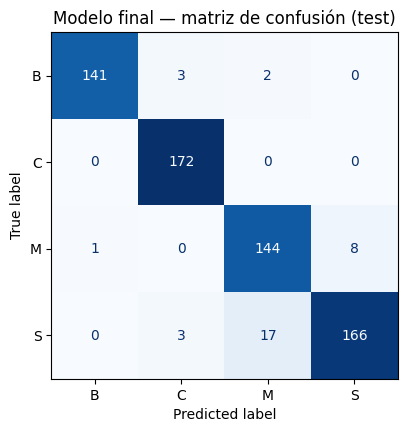

In [50]:
# 15.2 Evaluación ÚNICA sobre test del modelo seleccionado
pred_final = modelo_final.predict(X_test)
m_final = metricas_clf(y_test, pred_final)
registrar('15', 'Clasificación', 'MODELO FINAL: XGBoost ajustado (sin IDs)', m_final)
print(pd.Series(m_final).round(4).to_string())
print(classification_report(y_test, pred_final, digits=3))

# Incertidumbre del resultado de test: bootstrap de las 657 filas
rng = np.random.default_rng(RANDOM_STATE)
yt, yp = y_test.to_numpy(), np.asarray(pred_final)
boot = [f1_score(yt[i], yp[i], average='macro') for i in (rng.integers(0, len(yt), len(yt)) for _ in range(1000))]
ic = np.percentile(boot, [2.5, 97.5])
print(f'IC 95% bootstrap del F1 macro en test: [{ic[0]:.3f}, {ic[1]:.3f}]')

comparacion_final = pd.DataFrame({
    'F1_macro': [busqueda.best_score_, m_final['F1_macro'], metricas_clf(y_test, pred_base_clf)['F1_macro']],
}, index=['CV10 en train (selección)', 'Test (evaluación final)', 'Baseline en test'])
display(comparacion_final.round(4))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Modelo final — matriz de confusión (test)')
ax.grid(False)
plt.show()

In [51]:
# 15.3 README final del repositorio (se genera con los resultados de este notebook)
tabla_md = tabla_modelos[['F1_CV10_media', 'F1_CV10_std', 'F1_CV_grupos', 'F1_test_histórico']].round(3)
readme = f'''# Ortelana Textil — clasificación de `Format_Reporte`

Trabajo práctico integrador de IADS5. Proyecto de aprendizaje automático de punta a punta sobre
`ventas_historicas_ortelana_argentina.csv` ({len(df_raw)} registros sucursal × año × tela, 2016-2025).

## Problema
- **Principal (clasificación multiclase):** predecir `Format_Reporte` (B, C, M, S), es decir con qué formato
  de períodos fue cargado un registro, a partir de `Sucursal_ID`, `Año`, `Tela_ID`, `Metros1` y `Metros2`.
- **Secundario (regresión):** `Metros_Total`, metros vendidos en el año (suma de `Metros1..Metros12`),
  a partir de año, sucursal y tela.

## Decisiones principales
- Se excluyen `Metros3..Metros12`: su presencia o ausencia revela el formato (B tiene 6 períodos, M 12, C y S 2).
- Features derivadas fila a fila: `log_M1` y `log_ratio_M2_M1` = log(Metros2/Metros1).
- `Sucursal_ID` y `Tela_ID` son identificadores: con one-hot el modelo memoriza el formato de cada par
  sucursal-tela (cada par tiene siempre el mismo formato), así que el modelo final **no** los usa.
- Partición única 80/20 estratificada (`random_state=42`), persistida en `data/split_indices.csv`.
- Selección de modelos e hiperparámetros solo con validación cruzada sobre train; test se usó una vez
  para el modelo final (las métricas de test de actividades previas son históricas y no guiaron decisiones).

## Resultados (F1 macro)
{tabla_md.to_markdown()}

**Modelo final:** XGBoost `{MEJOR_CONFIG}` dentro de un `Pipeline`
(features → imputación + escalado → modelo).
- F1 macro CV10 (train): {busqueda.best_score_:.3f}
- **F1 macro test: {m_final["F1_macro"]:.3f}** (IC 95% bootstrap [{ic[0]:.3f}, {ic[1]:.3f}]), accuracy {m_final["Accuracy"]:.3f}
- Baseline (clase más frecuente) en test: {metricas_clf(y_test, pred_base_clf)["F1_macro"]:.3f}

## Estructura
```
ventas_historicas_ortelana_argentina.csv   dataset
IADS5_TP_Integrador_Ortelana_Cascallar-Kanesky-Luciani-Soriano.ipynb         notebook con las 16 actividades
data/split_indices.csv                     partición train/test
models/modelo_productivo.joblib            pipeline final serializado
src/ortelana_ml.py                         features y envoltorio de etiquetas (usados por el pipeline)
src/predecir.py                            script de predicción
outputs/                                   tablas y predicciones generadas
requirements.txt                           dependencias con versiones
```

## Reproducción
```bash
pip install -r requirements.txt
jupyter nbconvert --to notebook --execute --inplace IADS5_TP_Integrador_Ortelana_Cascallar-Kanesky-Luciani-Soriano.ipynb
python src/predecir.py --entrada outputs/ejemplo_entrada.csv --salida outputs/ejemplo_predicciones.csv
```
El CSV de entrada necesita las columnas {COLUMNAS_ENTRADA}.

## Limitaciones
- La partición aleatoria mezcla años y repite pares sucursal-tela entre train y test; el desempeño sobre pares
  nuevos se estimó aparte con validación agrupada (F1 macro {f1_grupos_final:.3f} para el modelo final).
- La confusión principal es entre C y S (ambos formatos de 2 períodos); el significado de cada código no está
  documentado en el dataset.
- No hay validación temporal (entrenar con años viejos y evaluar en años nuevos); es la próxima mejora sugerida.
'''
Path('README.md').write_text(readme, encoding='utf-8')
print(readme[:1500], '...')

# Ortelana Textil — clasificación de `Format_Reporte`

Trabajo práctico integrador de IADS5. Proyecto de aprendizaje automático de punta a punta sobre
`ventas_historicas_ortelana_argentina.csv` (3285 registros sucursal × año × tela, 2016-2025).

## Problema
- **Principal (clasificación multiclase):** predecir `Format_Reporte` (B, C, M, S), es decir con qué formato
  de períodos fue cargado un registro, a partir de `Sucursal_ID`, `Año`, `Tela_ID`, `Metros1` y `Metros2`.
- **Secundario (regresión):** `Metros_Total`, metros vendidos en el año (suma de `Metros1..Metros12`),
  a partir de año, sucursal y tela.

## Decisiones principales
- Se excluyen `Metros3..Metros12`: su presencia o ausencia revela el formato (B tiene 6 períodos, M 12, C y S 2).
- Features derivadas fila a fila: `log_M1` y `log_ratio_M2_M1` = log(Metros2/Metros1).
- `Sucursal_ID` y `Tela_ID` son identificadores: con one-hot el modelo memoriza el formato de cada par
  sucursal-tela (cada par tiene siempre el mismo formato

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Reproducibilidad:** releemos la partición desde el archivo y verificamos que coincide (MD5 registrado), y comprobamos que dos entrenamientos con la misma semilla producen probabilidades idénticas. El notebook se ejecuta de punta a punta sin intervención (las carpetas `data/`, `models/` y `outputs/` se crean solas).
- **Reentrenamiento:** el pipeline con la configuración elegida por `GridSearchCV` se reentrena con **todo train** (2.628 filas).
- **Evaluación única en test** (657 filas), con un intervalo de confianza bootstrap (1.000 remuestreos) para dimensionar la incertidumbre.
- La celda 15.3 genera el `README.md` final con los resultados del propio notebook.
- **Versionado** (lo hacemos al subir el repositorio): `git add .`, `git commit -m "release: modelo candidato final"`, `git tag v1.0` y `git push --tags`.

**Interpretación de los resultados:**
- **F1 macro en test = 0,9489** (IC 95% bootstrap: 0,932–0,965), accuracy 0,948 y F1 ponderado 0,948.
- Coincide con lo estimado por CV (0,9508) y cae dentro del rango previsto en la Act. 14 (0,933–0,968). No hay señales de sobreajuste a la validación. Frente a la baseline (0,110), la mejora es de 84 puntos.
- **Por clase:** C 0,983 (recall 1,00), B 0,979, S 0,922 (recall 0,892) y M 0,911 (precisión 0,883). Es el mismo patrón del análisis de errores en train: la debilidad está en distinguir S de M cuando el cociente es ≈ 1 y los volúmenes son bajos.

**Pregunta de análisis:** ¿Qué resultados son finales y cuáles provinieron de la búsqueda de modelos?
**Resultado final:** solo el F1 macro de test **0,9489** (y sus métricas asociadas) del modelo de la Act. 15. Es la única vez que el test se usó para evaluar el modelo elegido, sin que esa medición influyera en ninguna decisión.

**Resultados de la búsqueda de modelos:** todos los valores de CV de las actividades 3 a 14 (incluido el 0,9508 del `GridSearchCV`, que es levemente optimista porque es el máximo de 27 configuraciones) y las métricas de test "históricas" de las actividades anteriores. Esas últimas las reportamos porque la consigna lo pide, pero no las usamos para elegir. Hay un ejemplo concreto de por qué importa: el XGBoost con los hiperparámetros de la consigna tuvo un test histórico de **0,952**, mayor que el **0,949** del modelo final. Si hubiéramos elegido por test, habríamos tomado otra configuración por una diferencia de 0,3 puntos, muy chica frente a la amplitud del IC (3,3 puntos): una decisión basada en ruido.

**Limitaciones o mejoras posibles:**
Hay un solo conjunto de test, y su IC de ±1,6 puntos es la incertidumbre real del resultado. El desempeño sobre pares sucursal-tela nuevos se estimó con CV agrupada (0,938), no con test. Falta una validación temporal.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
## Actividad 16 · Serialización y defensa · Entrega final

**Qué se espera:** Serializá el pipeline con joblib en `models/modelo_productivo.joblib`, recargalo y comprobá predicciones idénticas; generá requirements.txt y `src/predecir.py` ejecutable; verificá repositorio y prepará defensa de 10–15 minutos.

**Evidencia a entregar:** Repositorio completo, modelo serializado, script, dependencias y defensa oral.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [52]:
# 16.1 Serialización con joblib y verificación de predicciones idénticas tras recargar
RUTA_MODELO = DIR_MODELS / 'modelo_productivo.joblib'
joblib.dump(modelo_final, RUTA_MODELO)
recargado = joblib.load(RUTA_MODELO)
assert np.array_equal(recargado.predict(X_test), modelo_final.predict(X_test))
assert np.allclose(recargado.predict_proba(X_test), modelo_final.predict_proba(X_test), atol=0, rtol=0)
print(f'Modelo guardado en {RUTA_MODELO} ({RUTA_MODELO.stat().st_size / 1024:.0f} KB)')
print('Predicciones y probabilidades idénticas tras recargar: OK')

Modelo guardado en models\modelo_productivo.joblib (356 KB)
Predicciones y probabilidades idénticas tras recargar: OK


In [53]:
# 16.2 requirements.txt con las versiones usadas
requirements = '\n'.join([f'numpy=={np.__version__}', f'pandas=={pd.__version__}', f'scikit-learn=={sklearn.__version__}',
                          f'xgboost=={xgboost.__version__}', f'scipy=={scipy.__version__}',
                          f'matplotlib=={matplotlib.__version__}', f'joblib=={joblib.__version__}',
                          'tabulate', 'jupyter']) + '\n'
Path('requirements.txt').write_text(requirements, encoding='utf-8')
print(requirements)

numpy==2.1.0
pandas==3.0.5
scikit-learn==1.9.0
xgboost==3.4.1
scipy==1.18.1
matplotlib==3.10.0
joblib==1.6.0
tabulate
jupyter



In [54]:
# 16.3 Prueba del script src/predecir.py como lo usaría un tercero (proceso separado)
entrada = test[COLUMNAS_ENTRADA].head(8).copy()
entrada.loc[entrada.index[0], 'Metros2'] = np.nan          # una fila con faltante
entrada.to_csv(DIR_OUT / 'ejemplo_entrada.csv', index=False)
proc = subprocess.run([sys.executable, 'src/predecir.py', '--entrada', str(DIR_OUT / 'ejemplo_entrada.csv'),
                       '--salida', str(DIR_OUT / 'ejemplo_predicciones.csv')], capture_output=True, text=True)
print(proc.stdout or proc.stderr)
assert proc.returncode == 0
display(pd.read_csv(DIR_OUT / 'ejemplo_predicciones.csv'))

8 predicciones guardadas en outputs\ejemplo_predicciones.csv
Format_Reporte_pred
S    3
M    2
B    2
C    1



,Sucursal_ID,Año,Tela_ID,Metros1,Metros2,Format_Reporte_pred,proba_B,proba_C,proba_M,proba_S
0,1,2016,TELA-006,342.56,NaN,M,0.0031,0.0010,0.7631,0.2329
1,1,2016,TELA-014,2549.20,1933.51,C,0.0005,0.9969,0.0002,0.0025
2,1,2016,TELA-015,1609.92,2320.64,B,0.9965,0.0003,0.0000,0.0032
3,1,2016,TELA-019,106.61,113.41,M,0.0006,0.0006,0.9797,0.0192
4,1,2016,TELA-022,3379.91,3369.55,S,0.0000,0.0008,0.0003,0.9988
5,1,2016,TELA-024,4722.31,4855.44,S,0.0000,0.0012,0.0002,0.9986
6,1,2016,TELA-025,1114.64,1502.95,B,0.9977,0.0002,0.0000,0.0020
7,1,2016,TELA-028,608.12,598.64,S,0.0024,0.0019,0.3660,0.6296


In [55]:
# 16.4 Verificación de los archivos del repositorio
archivos = ['README.md', 'requirements.txt', 'IADS5_TP_Integrador_Ortelana_Cascallar-Kanesky-Luciani-Soriano.ipynb', 'ventas_historicas_ortelana_argentina.csv',
            'data/split_indices.csv', 'models/modelo_productivo.joblib', 'src/__init__.py', 'src/ortelana_ml.py',
            'src/predecir.py', 'outputs/predicciones_baseline.csv', 'outputs/tabla_modelos_clasificacion.csv']
display(pd.DataFrame({'Existe': [Path(a).exists() for a in archivos]}, index=archivos))
print('Tabla final de modelos de clasificación (métricas de test históricas):')
display(tabla_historica('Clasificación').round(4))

,Existe
README.md,True
requirements.txt,True
IADS5_TP_Integrador_Ortelana_Cascallar-Kanesky-Luciani-Soriano.ipynb,True
ventas_historicas_ortelana_argentina.csv,True
data/split_indices.csv,True
models/modelo_productivo.joblib,True
src/__init__.py,True
src/ortelana_ml.py,True
src/predecir.py,True
outputs/predicciones_baseline.csv,True


Tabla final de modelos de clasificación (métricas de test históricas):


,Actividad,Accuracy,F1_macro,F1_weighted
Modelo,,,,
Baseline (más frecuente),01-02,0.2831,0.1103,0.1249
"LogReg (Año, Metros1, Metros2 crudas)",03,0.7336,0.7296,0.7356
"LogReg (Año, log_M1, log_ratio)",03,0.7686,0.7686,0.7670
Árbol gini (max_depth=4),05,0.9346,0.9357,0.9345
Árbol entropy (max_depth=4),05,0.9346,0.9358,0.9344
Random Forest (100 árboles),06,0.9422,0.9428,0.9421
"XGBoost (100, lr=0.1, depth=3)",06,0.9513,0.9519,0.9513
Random Forest + IDs one-hot (pipeline),09,0.9878,0.9876,0.9878
Random Forest sin IDs (pipeline),09,0.9422,0.9428,0.9421


### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- Serializamos **el pipeline completo** (features → imputación + escalado → XGBoost con decodificación de etiquetas) con `joblib` en `models/modelo_productivo.joblib`. Al recargarlo, verificamos con `assert` que las predicciones y las probabilidades son idénticas.
- Las funciones propias están en `src/ortelana_ml.py`: el pickle las referencia por módulo, así que cualquier script que importe `src` puede cargar el modelo.
- `requirements.txt` con las versiones exactas usadas.
- `src/predecir.py`: script de línea de comandos que valida las columnas requeridas y devuelve la clase y la probabilidad de cada formato. Lo probamos **en un proceso separado**, con una fila con faltante.
- Verificamos que existan todos los archivos del repositorio.

**Interpretación de los resultados:**
- El modelo pesa 356 KB y las predicciones y probabilidades son idénticas después de recargarlo.
- El script procesó 8 registros sin errores. La fila con `Metros2` faltante se predijo como M (P = 0,76), que es su clase real. La fila con P(S) = 0,63 y P(M) = 0,37 es un ejemplo de la zona de confusión S/M, donde conviene una revisión manual.
- Los archivos requeridos (README, requirements, notebook, dataset, partición, modelo, `src/` y salidas) existen.

**Guion de la defensa (10–15 minutos):**
1. *Problema y datos (2 min):* qué es `Format_Reporte` y la evidencia de que indica la cantidad de períodos.
2. *Riesgos de fuga (3 min):* el proxy `Metros3..12`, la dependencia por par sucursal-tela (360 pares con formato constante) y la CV agrupada que la deja en evidencia.
3. *Recorrido de modelos (3 min):* baseline 0,11 → LogReg 0,76 → árbol 0,94 → ensambles 0,95. Por qué el cociente de metros es la feature clave.
4. *Selección y ajuste (2 min):* tabla de la Act. 13, por qué no se eligió RF + IDs y la meseta del `GridSearchCV`.
5. *Resultado final y producción (2 min):* test 0,949 [0,932–0,965], demostración de `src/predecir.py`.
6. *Limitaciones y próximos pasos (1–2 min):* confusión S/M, validación temporal y monitoreo.

**Pregunta de análisis:** ¿Cómo evitaste data leakage? ¿Qué limitaciones tiene el modelo y cómo lo monitorearías?
**Cómo evitamos la fuga:**
1. Excluimos `Metros3..12`, cuya presencia revela el formato.
2. Hicimos una **única partición** persistida. El test se usó para la evaluación final y las métricas "históricas" que pide la consigna no guiaron decisiones. Toda la selección (modelo, k, alpha, profundidad, hiperparámetros) se hizo con CV sobre train.
3. Todo el preprocesamiento que se ajusta con datos (imputación, escalado, one-hot) está **dentro del `Pipeline`**, así que se reajusta en cada fold.
4. Las features derivadas son fila a fila.
5. Detectamos la memorización por par con CV agrupada y **excluimos los IDs** del modelo final.
6. El clustering no usó el target.
7. En la regresión, no usamos ningún componente del total como feature.

**Limitaciones:**
- El split aleatorio no simula datos futuros.
- El significado de C y S no está documentado.
- El modelo depende de que `Metros1` y `Metros2` existan y sean positivos (imputar uno distorsiona el cociente).
- Confunde S con M en registros de bajo volumen.
- No puede reconocer un formato nuevo.
- Fue entrenado con datos de 2016–2025.

**Monitoreo:**
- Comparar periódicamente la distribución de clases predichas con la histórica (22–28% por clase).
- Vigilar el *drift* de `log_M1` y del cociente (por ejemplo, con PSI) y el porcentaje de entradas con faltantes.
- Con una muestra etiquetada mensual, calcular el F1 macro y el recall de S y M.
- Derivar a revisión los casos con probabilidad máxima < 0,6.
- Reentrenar si el F1 cae por debajo de ~0,93 (el límite inferior del IC) o si aparecen sucursales, telas o formatos nuevos.

**Limitaciones o mejoras posibles:**
Agregar una validación temporal, una regla de abstención para entradas con faltantes, explicaciones por caso (SHAP) y tests automáticos del script (por ejemplo, con `pytest`) que verifiquen columnas, tipos y la estabilidad de las predicciones.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]


---
# Evaluación global del TP integrador

**Rúbrica sugerida para la evaluación global del trabajo** (orientativa; el enunciado remite a una rúbrica final de clase 16 que no está incluida en el documento proporcionado):

| Criterio | Máximo | Puntaje docente |
|---|---:|---:|
| Cumplimiento de consignas y evidencias | 30 | ____ |
| Corrección técnica y ausencia de leakage | 25 | ____ |
| Interpretación y justificación | 25 | ____ |
| Reproducibilidad, claridad y documentación | 20 | ____ |
| **Total** | **100** | **____** |

**Calificación única del TP integrador:** [____ / 10]  
**Peso de la entrega final según el enunciado:** 60% de la calificación de la materia. **La ponderación restante no se define en este cuaderno.**

**Devolución final del docente:**  
[Escribí aquí una devolución global.]

**Preguntas para la defensa oral:**  
[Anotá preguntas y respuestas observadas.]

**Resultado final:** [Aprobado / Reentrega / Pendiente]

**Docente:** [Nombre]  
**Fecha de corrección:** [Fecha]
